# Surrogate diagnostics: run 2 results overview

Run all cells using the Python kernel from **ligoopt** to refresh this report from saved files in
`analysis/surrogate_diagnostics/outputs/`. Open the notebook from the repository root
or this directory. New audit and evaluation folders are discovered automatically.

This report covers data coverage, inference features, fitting and held-out metrics,
training curves, signed perturbation responses, perturbation costs, and source
provenance. It reads saved CSV/JSON files; refreshing it does not train models or
run Finesse simulations. Figures can optionally be exported as PNG files.

**Interpretation:** tiny-fit results measure reconstruction of training examples.
`generalization_smoke` contains only five epochs and checks the workflow. Standalone
evaluation of an existing checkpoint does not establish independence from training.
Compare loss variants within the same experiment, split, detector, and seed.

This notebook includes only run 2 output folders, selected from saved configs. Open [run 3 results](results_overview_run3.ipynb) for the other run.


In [1]:
import csv
import html
import json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
import numpy as np
from IPython.display import HTML, Image, Markdown, display

REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'analysis/surrogate_diagnostics').is_dir() and (p / 'MLP').is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook with a working directory inside ligo-opt.')
DIAGNOSTICS_DIR = REPO_ROOT / 'analysis/surrogate_diagnostics'
OUTPUTS_DIR = DIAGNOSTICS_DIR / 'outputs'

RUN_NUMBER = 2
# None includes every saved experiment for this run. Example: {'round10_tiny', 'round10_warm_start'}.
EXPERIMENT_FILTER = None
INCLUDE_SMOKE = True
DELTA_ERROR_TARGET_W = 0.1
TOP_ERRORS_PER_RUN_SPLIT = 3
EXPORT_FIGURES = False
EXPORT_DIR = OUTPUTS_DIR / f'notebook_figures_run{RUN_NUMBER}'

# Change these and rerun the group-response cell to inspect any saved feedback group.
DETAIL_EXPERIMENT = 'round10_tiny'
DETAIL_SPLIT = 'train'
DETAIL_GROUP = 'round:10:0'
SHOW_ALL_GROUP_RESPONSES = False
SHOW_SAVED_FIGURES = False

DIRECTIONS = ['nominal', 'ITM_plus', 'ITM_minus', 'ETM_plus', 'ETM_minus', 'joint']
SPLITS = ['train', 'validation', 'test', 'all']
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 140, 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.2, 'axes.spines.top': False,
    'axes.spines.right': False,
})
print(f'Reading: {OUTPUTS_DIR}')


Reading: /home/xuesi.ma/ligo-opt/analysis/surrogate_diagnostics/outputs


## Load and inspect the saved artifacts

Every run 2 `audit.json` and `metrics.json` is included. Metrics are read directly so that
standalone checkpoint evaluations, which have no `summary.csv`, are included too.
Tables use expandable panels for complete sample-level results.


In [2]:
def read_json(path):
    return json.loads(path.read_text()) if path.exists() else {}


def read_csv(path):
    if not path.exists():
        return []
    def convert(value):
        if value == '':
            return None
        if value in ('True', 'False'):
            return value == 'True'
        try:
            return int(value)
        except ValueError:
            try:
                return float(value)
            except ValueError:
                return value
    with path.open(newline='') as stream:
        return [{k: convert(v) for k, v in row.items()} for row in csv.DictReader(stream)]


def formatted(value):
    if value is None:
        return '—'
    if isinstance(value, (float, np.floating)):
        return f'{value:.6g}'
    return str(value)


def table(rows, columns=None, title=None, collapsed=False):
    if not rows:
        display(Markdown(f'**{title or "Table"}:** no saved rows.'))
        return
    columns = columns or list(dict.fromkeys(k for row in rows for k in row))
    header = ''.join(f'<th>{html.escape(k)}</th>' for k in columns)
    body = ''.join('<tr>' + ''.join(
        f'<td>{html.escape(formatted(row.get(k)))}</td>' for k in columns
    ) + '</tr>' for row in rows)
    content = (
        '<div style="max-height:480px;overflow:auto">'
        '<table style="border-collapse:collapse;text-align:left;font-size:12px">'
        f'<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table></div>'
    )
    caption = html.escape(f'{title or "Rows"} ({len(rows)} rows)')
    if collapsed:
        content = f'<details><summary>{caption}</summary>{content}</details>'
    else:
        content = f'<p><b>{caption}</b></p>{content}'
    display(HTML(content))


def json_panel(title, value):
    text = html.escape(json.dumps(value, indent=2))
    display(HTML(f'<details><summary>{html.escape(title)}</summary>'
                 f'<pre style="max-height:450px;overflow:auto">{text}</pre></details>'))


figure_count = 0
def show_figure(fig, name):
    global figure_count
    figure_count += 1
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        safe_name = ''.join(c if c.isalnum() or c in '-_' else '_' for c in name)
        fig.savefig(EXPORT_DIR / f'{safe_name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def values(rows, field):
    return np.array([r[field] if r.get(field) is not None else np.nan for r in rows], dtype=float)


def parity_line(ax, x, y):
    both = np.concatenate([np.asarray(x), np.asarray(y)])
    both = both[np.isfinite(both)]
    if not len(both):
        return
    lo, hi = both.min(), both.max()
    pad = max((hi - lo) * 0.05, abs(hi) * 0.02, 1e-6)
    limits = (lo - pad, hi + pad)
    ax.plot(limits, limits, '--', color='black', lw=1, label='Exact agreement')
    ax.set_xlim(limits)
    ax.set_ylim(limits)


def artifact_run(name):
    # The parent experiment owns cross-run comparisons, including reference checkpoints.
    directory = OUTPUTS_DIR / name.split('/')[0]
    config = read_json(directory / 'config.json')
    if config.get('target_run') is not None:
        return int(config['target_run'])
    data_name = Path(config.get('data_dir') or '').name
    if data_name.startswith('run') and data_name[3:].isdigit():
        return int(data_name[3:])
    # Training audits have no config.json; named run folders retain automatic discovery.
    folder_run = directory.name.split('_')[0]
    if folder_run.startswith('run') and folder_run[3:].isdigit():
        return int(folder_run[3:])
    return None


def included(name):
    return artifact_run(name) == RUN_NUMBER and (
        EXPERIMENT_FILTER is None or name in EXPERIMENT_FILTER
    ) and (INCLUDE_SMOKE or 'smoke' not in name.lower())


audits, runs, experiments = {}, {}, {}
predictions_rows, metric_rows, direction_rows, cost_rows, history_rows = [], [], [], [], []
for path in sorted(OUTPUTS_DIR.rglob('audit.json')):
    name = path.parent.relative_to(OUTPUTS_DIR).as_posix()
    if included(name):
        audits[name] = {'path': path.parent, 'audit': read_json(path),
                        'config': read_json(path.parent / 'config.json'),
                        'samples': read_csv(path.parent / 'samples.csv'),
                        'features': read_csv(path.parent / 'inference_features.csv')}

for path in sorted(OUTPUTS_DIR.rglob('metrics.json')):
    directory = path.parent
    experiment_dir = directory
    for parent in (directory, *directory.parents):
        if parent == OUTPUTS_DIR:
            break
        if (parent / 'summary.csv').exists() or (parent / 'provenance.json').exists():
            experiment_dir = parent
            break
    experiment = experiment_dir.relative_to(OUTPUTS_DIR).as_posix()
    if not included(experiment):
        continue
    run_id = directory.relative_to(OUTPUTS_DIR).as_posix()
    config = read_json(directory / 'config.json')
    metrics = read_json(path)
    # Initial datasets differ between runs; give each original split its own
    # experiment instead of combining nominal/joint and five-point labels.
    if metrics.get('checkpoint_training_metadata') and 'feedback' not in metrics.get('splits', {}):
        experiment_dir = directory
        experiment = run_id
    scope = ('standalone checkpoint evaluation' if metrics.get('checkpoint') else
             'generalization smoke run' if 'smoke' in experiment.lower() else
             'training-set fit' if metrics.get('mode', config.get('mode')) == 'tiny_fit' else
             'grouped generalization')
    tags = {'experiment': experiment, 'run_id': run_id,
            'variant': config.get('variant', 'checkpoint'), 'seed': config.get('seed'),
            'detector': config.get('detector'), 'scope': scope}
    current_predictions = [{**row, **tags} for row in read_csv(directory / 'predictions.csv')]
    current_history = [{**row, **tags} for row in read_csv(directory / 'training_history.csv')]
    runs[run_id] = {'path': directory, 'config': config, 'metrics': metrics, 'tags': tags,
                    'predictions': current_predictions, 'history': current_history}
    experiments[experiment] = {'path': experiment_dir,
                               'config': read_json(experiment_dir / 'config.json'),
                               'provenance': read_json(experiment_dir / 'provenance.json'),
                               'scope': scope}
    predictions_rows.extend(current_predictions)
    history_rows.extend(current_history)
    for split, result in metrics.get('splits', {}).items():
        metric_rows.append({**tags, 'split': split, 'best_epoch': metrics.get('best_epoch'),
                            'monitor_split': metrics.get('monitor_split'),
                            **{k: v for k, v in result.items() if k != 'by_direction'}})
        for direction, stats in result.get('by_direction', {}).items():
            direction_rows.append({**tags, 'split': split, 'direction': direction, **stats})
    for split, costs in read_json(directory / 'costs.json').items():
        for row in costs:
            valid = row.get('true_perturbation_cost') is not None and row.get('predicted_perturbation_cost') is not None
            cost_rows.append({**tags, 'split': split, **row,
                              'cost_error': row['predicted_perturbation_cost'] - row['true_perturbation_cost'] if valid else None})

if not audits and not runs:
    display(Markdown('No saved diagnostic outputs match the current filters. '
                     'Run an audit/evaluation using the commands in README.md, then refresh this notebook.'))
print(f'{len(audits)} audits; {len(experiments)} evaluation/fit experiments; '
      f'{len(runs)} checkpoints; {len(metric_rows)} run/split metric rows; '
      f'{len(predictions_rows)} predictions.')


2 audits; 4 evaluation/fit experiments; 10 checkpoints; 16 run/split metric rows; 1129 predictions.


In [3]:
inventory = []
for name, record in sorted({**audits, **experiments}.items()):
    paths = [p for p in record['path'].rglob('*') if p.is_file()]
    inventory.append({
        'folder': name, 'scope': 'data / feature audit' if name in audits else record['scope'],
        'files': len(paths), 'CSV': sum(p.suffix == '.csv' for p in paths),
        'JSON': sum(p.suffix == '.json' for p in paths),
        'PNG': sum(p.suffix == '.png' for p in paths),
        'checkpoints': sum(p.suffix == '.pt' for p in paths),
    })
table(inventory, title='Saved output folders')
artifact_rows = [{'path': p.relative_to(DIAGNOSTICS_DIR).as_posix(),
                  'bytes': p.stat().st_size}
                 for p in sorted(OUTPUTS_DIR.rglob('*'))
                 if p.is_file() and included(p.relative_to(OUTPUTS_DIR).parts[0])]
table(artifact_rows, title='Complete artifact inventory', collapsed=True)


folder,scope,files,CSV,JSON,PNG,checkpoints
base_on_selected_rounds,standalone checkpoint evaluation,4,1,3,0,0
generalization_smoke,generalization smoke run,21,7,11,0,3
round10_tiny,training-set fit,31,7,11,10,3
round10_warm_start,training-set fit,31,7,11,10,3
run2_audit,data / feature audit,3,1,2,0,0
run2_selected_feature_audit,data / feature audit,4,2,2,0,0


path,bytes
outputs/base_on_selected_rounds/config.json,845
outputs/base_on_selected_rounds/costs.json,784
outputs/base_on_selected_rounds/metrics.json,1541
outputs/base_on_selected_rounds/predictions.csv,7721
outputs/generalization_smoke/center_focused_seed9302/checkpoint.pt,21732
outputs/generalization_smoke/center_focused_seed9302/config.json,2830
outputs/generalization_smoke/center_focused_seed9302/costs.json,6298
outputs/generalization_smoke/center_focused_seed9302/metrics.json,4858
outputs/generalization_smoke/center_focused_seed9302/predictions.csv,107598
outputs/generalization_smoke/center_focused_seed9302/training_history.csv,432


## Data coverage and label audit

The audits include invalid fixed-q groups and zero-output rows. A zero label alone
cannot distinguish an unstable cavity from a solver or lock failure. Historical
run 2 initial data uses nominal/joint pairs; run 3 initial data records five-row
nominal/ITM+/ITM-/ETM+/ETM- groups. Initial joint ROC perturbations stay separate
from single-mirror directions. The center band comes from each saved config.


audit,groups,rows,valid_fixed_q_groups,zero_output_rows,center_rows,invalid_fixed_q_groups,power_range_W,delta_range_W,feature_check_rows,feature_mismatches,detector
run2_audit,140,400,119,41,86,21,"[0.0, 282.09411094292744]","[-106.15711212158203, 65.87445831298828]",—,—,p_ITM_p2_i
run2_selected_feature_audit,5,25,5,0,0,0,"[7.480780185775772, 192.72857088529577]","[-15.922419548034668, 14.629744529724121]",25,0,p_ITM_p2_i


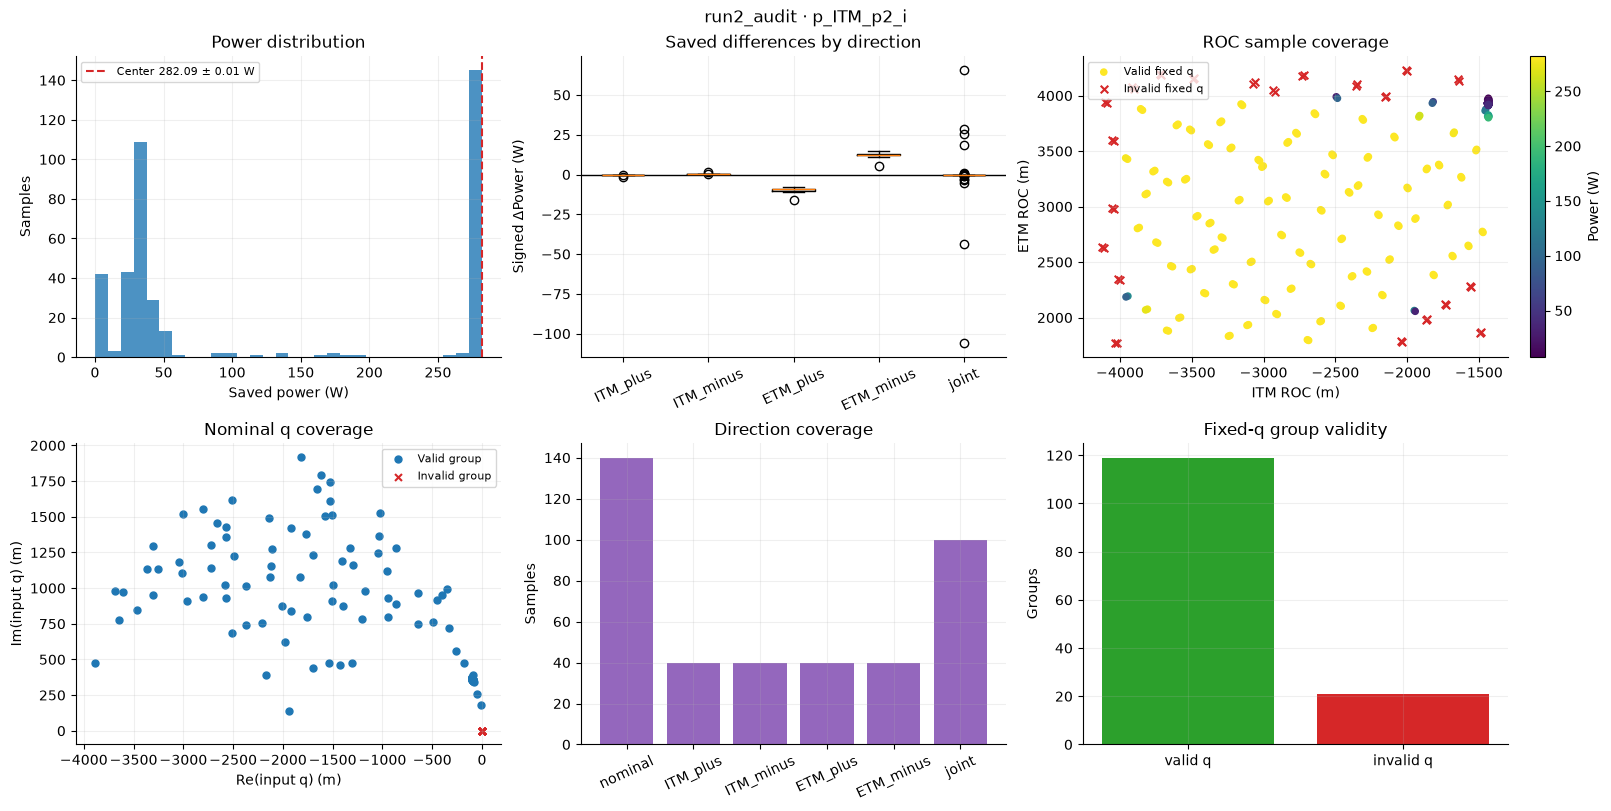

feature,minimum,maximum,std
ITM ROC (m),-4125.15,-1429.27,871.685
ETM ROC (m),1766.97,4233.51,691.834
Re(q) (m),-3887.47,0,1063.36
Im(q) (m),0,1918.67,446.739


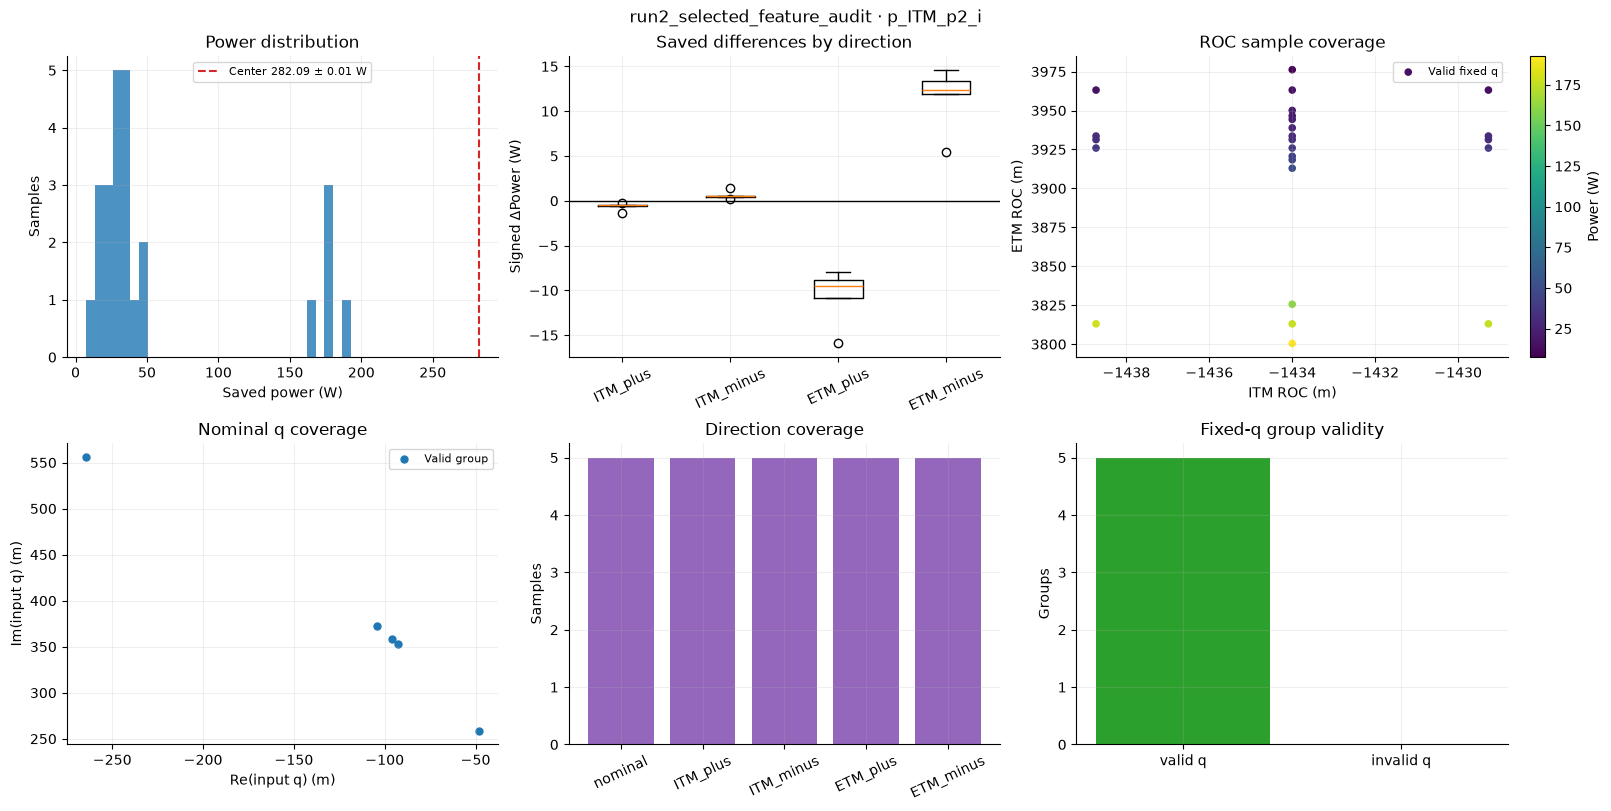

feature,minimum,maximum,std
ITM ROC (m),-1438.73,-1429.27,2.99289
ETM ROC (m),3800.46,3976.21,52.4719
Re(q) (m),-264.308,-48.2916,74.1977
Im(q) (m),258.685,556.02,96.9203


In [4]:
audit_rows = []
for name, record in audits.items():
    audit = record['audit']
    check = audit.get('inference_check') or {}
    audit_rows.append({
        'audit': name, **{k: audit.get(k) for k in
            ('groups', 'rows', 'valid_fixed_q_groups', 'zero_output_rows', 'center_rows')},
        'invalid_fixed_q_groups': audit.get('groups', 0) - audit.get('valid_fixed_q_groups', 0),
        'power_range_W': audit.get('power_range_w'),
        'delta_range_W': audit.get('delta_range_w'),
        'feature_check_rows': check.get('rows'), 'feature_mismatches': check.get('mismatches'),
        'detector': record['config'].get('detector'),
    })
table(audit_rows, title='Audit totals (each audit is a separate sample selection)')

for name, record in audits.items():
    rows, audit = record['samples'], record['audit']
    if not rows:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    axes[0, 0].hist(values(rows, 'power'), bins=30, color='tab:blue', alpha=0.8)
    center = record['config'].get('center_loss', {})
    if center:
        axes[0, 0].axvline(center['center_power'], color='tab:red', ls='--',
                          label=f"Center {center['center_power']} ± {center['center_width']} W")
        axes[0, 0].legend(fontsize=8)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='Samples', title='Power distribution')
    directions = [d for d in DIRECTIONS if d != 'nominal' and any(r['direction'] == d for r in rows)]
    if directions:
        axes[0, 1].boxplot([values([r for r in rows if r['direction'] == d], 'delta_power') for d in directions])
        axes[0, 1].set_xticks(range(1, len(directions) + 1), directions, rotation=25)
    axes[0, 1].axhline(0, color='black', lw=1)
    axes[0, 1].set(ylabel='Signed ΔPower (W)', title='Saved differences by direction')
    valid = [r for r in rows if r.get('valid_fixed_q_group')]
    invalid = [r for r in rows if not r.get('valid_fixed_q_group')]
    scatter = axes[0, 2].scatter(values(valid, 'ITM_Rc'), values(valid, 'ETM_Rc'),
                                c=values(valid, 'power'), s=20, cmap='viridis', label='Valid fixed q')
    if invalid:
        axes[0, 2].scatter(values(invalid, 'ITM_Rc'), values(invalid, 'ETM_Rc'),
                           marker='x', color='tab:red', s=30, label='Invalid fixed q')
    fig.colorbar(scatter, ax=axes[0, 2], label='Power (W)')
    axes[0, 2].set(xlabel='ITM ROC (m)', ylabel='ETM ROC (m)', title='ROC sample coverage')
    axes[0, 2].legend(fontsize=8)
    nominal = [r for r in rows if r['direction'] == 'nominal']
    for status, marker, color in ((True, 'o', 'tab:blue'), (False, 'x', 'tab:red')):
        subset = [r for r in nominal if bool(r.get('valid_fixed_q_group')) == status]
        if subset:
            axes[1, 0].scatter(values(subset, 'q_input_real'), values(subset, 'q_input_imag'),
                               marker=marker, color=color, s=25,
                               label='Valid group' if status else 'Invalid group')
    axes[1, 0].set(xlabel='Re(input q) (m)', ylabel='Im(input q) (m)', title='Nominal q coverage')
    axes[1, 0].legend(fontsize=8)
    counts = Counter(r['direction'] for r in rows)
    present = [d for d in DIRECTIONS if d in counts]
    axes[1, 1].bar(present, [counts[d] for d in present], color='tab:purple')
    axes[1, 1].tick_params(axis='x', rotation=25)
    axes[1, 1].set(ylabel='Samples', title='Direction coverage')
    axes[1, 2].bar(['valid q', 'invalid q'],
                   [audit['valid_fixed_q_groups'], audit['groups'] - audit['valid_fixed_q_groups']],
                   color=['tab:green', 'tab:red'])
    axes[1, 2].set(ylabel='Groups', title='Fixed-q group validity')
    fig.suptitle(f'{name} · {record["config"].get("detector", "detector unspecified")}')
    show_figure(fig, f'audit_{name}')
    feature_stats = [{'feature': feature, 'minimum': lo, 'maximum': hi, 'std': std}
                     for feature, lo, hi, std in zip(
                         ['ITM ROC (m)', 'ETM ROC (m)', 'Re(q) (m)', 'Im(q) (m)'],
                         audit.get('feature_min', []), audit.get('feature_max', []), audit.get('feature_std', []))]
    table(feature_stats, title=f'{name}: feature ranges')


## Production feature reconstruction

The saved pass/fail flags use relative tolerance `2e-4` and absolute tolerance `0.05`
on features reconstructed from float32 inputs. Use those flags when judging agreement;
a single cutoff on the maximum error would not reproduce the check. Agreement
supports feature plumbing for these rows, rather than validating optical labels.


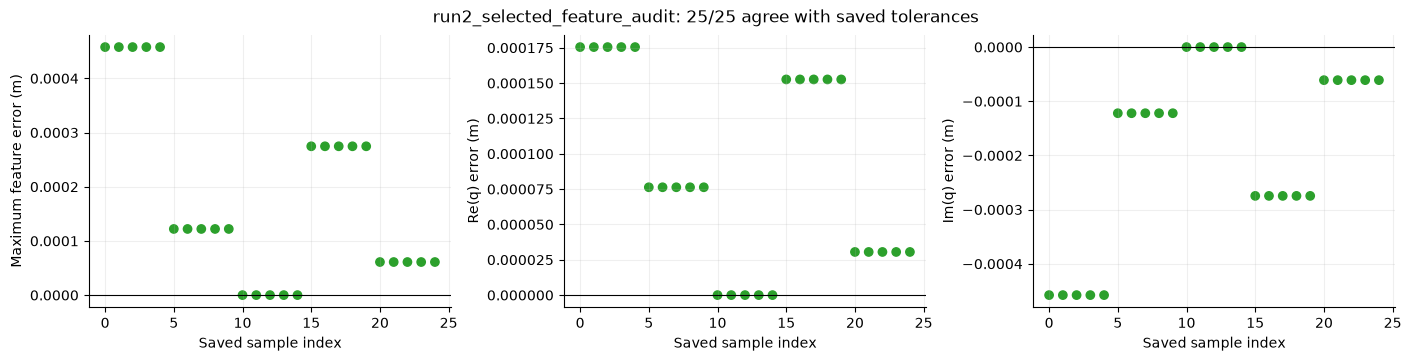

audit,group_id,h5_key,max_feature_abs_error,q_real_error,q_imag_error,matches_tolerance,trace_valid
run2_selected_feature_audit,round:1:0,sim_0,0.000457764,0.000175476,-0.000457764,True,True
run2_selected_feature_audit,round:1:0,sim_1,0.000457764,0.000175476,-0.000457764,True,True
run2_selected_feature_audit,round:1:0,sim_2,0.000457764,0.000175476,-0.000457764,True,True
run2_selected_feature_audit,round:1:0,sim_3,0.000457764,0.000175476,-0.000457764,True,True
run2_selected_feature_audit,round:1:0,sim_4,0.000457764,0.000175476,-0.000457764,True,True
run2_selected_feature_audit,round:10:0,sim_0,0.00012207,7.62939e-05,-0.00012207,True,True
run2_selected_feature_audit,round:10:0,sim_1,0.00012207,7.62939e-05,-0.00012207,True,True
run2_selected_feature_audit,round:10:0,sim_2,0.00012207,7.62939e-05,-0.00012207,True,True
run2_selected_feature_audit,round:10:0,sim_3,0.00012207,7.62939e-05,-0.00012207,True,True
run2_selected_feature_audit,round:10:0,sim_4,0.00012207,7.62939e-05,-0.00012207,True,True


In [5]:
feature_checks = []
for name, record in audits.items():
    rows = record['features']
    if not rows:
        continue
    feature_checks.extend({'audit': name, **row} for row in rows)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
    colors = ['tab:green' if r.get('matches_tolerance') and r.get('trace_valid') else 'tab:red' for r in rows]
    for ax, field, label in zip(axes,
            ['max_feature_abs_error', 'q_real_error', 'q_imag_error'],
            ['Maximum feature error (m)', 'Re(q) error (m)', 'Im(q) error (m)']):
        ax.scatter(range(len(rows)), values(rows, field), c=colors)
        ax.axhline(0, color='black', lw=0.8)
        ax.set(xlabel='Saved sample index', ylabel=label)
    passed = sum(bool(r.get('matches_tolerance')) for r in rows)
    fig.suptitle(f'{name}: {passed}/{len(rows)} agree with saved tolerances')
    show_figure(fig, f'feature_check_{name}')
table(feature_checks, title='All reconstructed-feature checks')


## Experiment conditions and comparable results

Scratch/local scaling and warm-start/original scaling change both initialization
and normalization. Their difference cannot be attributed solely to the loss.
Checkpoint selection uses the monitored split and the saved training-only scales:

`power_MAE / training_power_RMS + delta_MAE / training_delta_RMS`.

Sign accuracy excludes true `|ΔPower|` at or below the saved threshold (currently
0.1 W); the significant sample count is shown alongside it.

Grouped holdouts measure saved designs. Nearby PSO geometries can remain correlated,
so these splits do not establish spatial extrapolation. Use validation for choosing
settings; repeatedly choosing variants from test results compromises the holdout.


In [6]:
condition_rows, initialization_rows = [], []
for name, experiment in experiments.items():
    config, provenance = experiment['config'], experiment['provenance']
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == name]
    first = selected_runs[0]
    sizes = {split: stats['groups'] for split, stats in first['metrics'].get('splits', {}).items()}
    excluded = provenance.get('excluded_invalid_fixed_q_groups', first['metrics'].get('excluded', {}))
    condition_rows.append({
        'experiment': name, 'scope': experiment['scope'], 'detector': config.get('detector'),
        'initial_checkpoint': first['metrics'].get('checkpoint') or config.get('initial_checkpoint') or 'fresh weights',
        'normalization': 'checkpoint (evaluation)' if first['metrics'].get('checkpoint') else config.get('normalization'),
        'epochs': config.get('epochs') if first['history'] else None,
        'monitor_split': first['metrics'].get('monitor_split'),
        'groups_by_split': sizes, 'excluded_groups': {k: len(v) for k, v in excluded.items()},
        'power_scale_W': provenance.get('power_scale_w'), 'delta_scale_W': provenance.get('delta_scale_w'),
    })
    seeds = sorted({r['config'].get('seed') for r in selected_runs if r['config'].get('seed') is not None})
    for seed in seeds:
        hashes = {r['config'].get('initial_state_sha256') for r in selected_runs if r['config'].get('seed') == seed}
        hashes.discard(None)
        initialization_rows.append({'experiment': name, 'seed': seed, 'recorded_initial_states': len(hashes),
                                    'same_start_across_variants': len(hashes) == 1 if hashes else None})
table(condition_rows, title='Saved experimental conditions')
table(initialization_rows, title='Initialization consistency within each experiment / seed')
table(metric_rows, columns=['experiment', 'variant', 'seed', 'split', 'detector', 'best_epoch',
    'groups', 'rows', 'power_mae', 'power_max_abs_error', 'delta_mae', 'delta_max_abs_error',
    'sign_accuracy', 'sign_count', 'sign_threshold_w', 'perturbation_cost_mae',
    'valid_cost_groups', 'invalid_cost_groups'], title='All saved metrics')


experiment,scope,detector,initial_checkpoint,normalization,epochs,monitor_split,groups_by_split,excluded_groups,power_scale_W,delta_scale_W
base_on_selected_rounds,standalone checkpoint evaluation,p_ITM_p2_i,/home/xuesi.ma/ligo-opt/MLP/models/run2/base_200_mlp.pt,checkpoint (evaluation),—,—,{'train': 5},{'train': 0},—,—
generalization_smoke,generalization smoke run,p_ITM_p2_i,fresh weights,training,5,validation,"{'train': 78, 'validation': 20, 'test': 21}","{'train': 16, 'validation': 3, 'test': 2}",187.386,12.8823
round10_tiny,training-set fit,p_ITM_p2_i,fresh weights,training,2000,train,{'train': 1},{'train': 0},38.4907,8.64845
round10_warm_start,training-set fit,p_ITM_p2_i,MLP/models/run2/base_200_mlp.pt,checkpoint,2000,train,{'train': 1},{'train': 0},38.4907,8.64845


experiment,seed,recorded_initial_states,same_start_across_variants
generalization_smoke,9302,1,True
round10_tiny,9302,1,True
round10_warm_start,9302,1,True


experiment,variant,seed,split,detector,best_epoch,groups,rows,power_mae,power_max_abs_error,delta_mae,delta_max_abs_error,sign_accuracy,sign_count,sign_threshold_w,perturbation_cost_mae,valid_cost_groups,invalid_cost_groups
base_on_selected_rounds,checkpoint,—,train,p_ITM_p2_i,—,5,25,28.9478,52.4341,6.21097,17.0866,0,20,0.1,1.85842,5,0
generalization_smoke,center_focused,9302,train,p_ITM_p2_i,5,78,228,141.748,281.004,5.57813,106.158,0.936937,111,0.1,1.94019,24,0
generalization_smoke,center_focused,9302,validation,p_ITM_p2_i,5,20,64,124.283,280.928,4.0229,12.3937,1,35,0.1,1.81845,8,0
generalization_smoke,center_focused,9302,test,p_ITM_p2_i,5,21,66,140.027,281,4.21893,15.9215,0.971429,35,0.1,1.95643,8,0
generalization_smoke,log_smooth_l1,9302,train,p_ITM_p2_i,5,78,228,141.725,281.008,5.57839,106.158,0.918919,111,0.1,1.94033,24,0
generalization_smoke,log_smooth_l1,9302,validation,p_ITM_p2_i,5,20,64,124.258,280.951,4.02319,12.3943,1,35,0.1,1.81858,8,0
generalization_smoke,log_smooth_l1,9302,test,p_ITM_p2_i,5,21,66,140.002,281.01,4.21917,15.9221,0.971429,35,0.1,1.95656,8,0
generalization_smoke,paired,9302,train,p_ITM_p2_i,5,78,228,141.725,281.008,5.57839,106.158,0.918919,111,0.1,1.94033,24,0
generalization_smoke,paired,9302,validation,p_ITM_p2_i,5,20,64,124.258,280.951,4.02319,12.3943,1,35,0.1,1.81858,8,0
generalization_smoke,paired,9302,test,p_ITM_p2_i,5,21,66,140.002,281.01,4.21917,15.9221,0.971429,35,0.1,1.95656,8,0


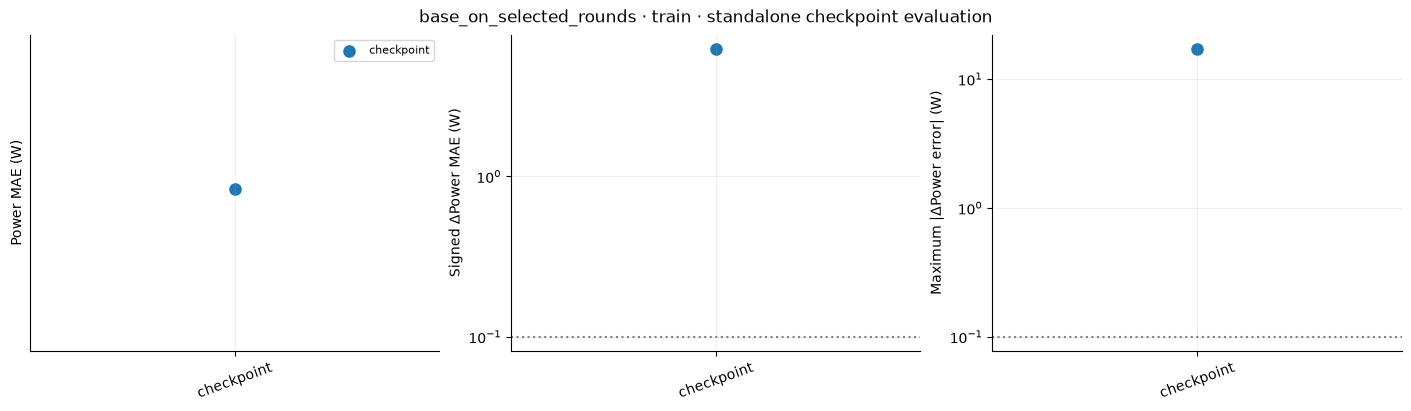

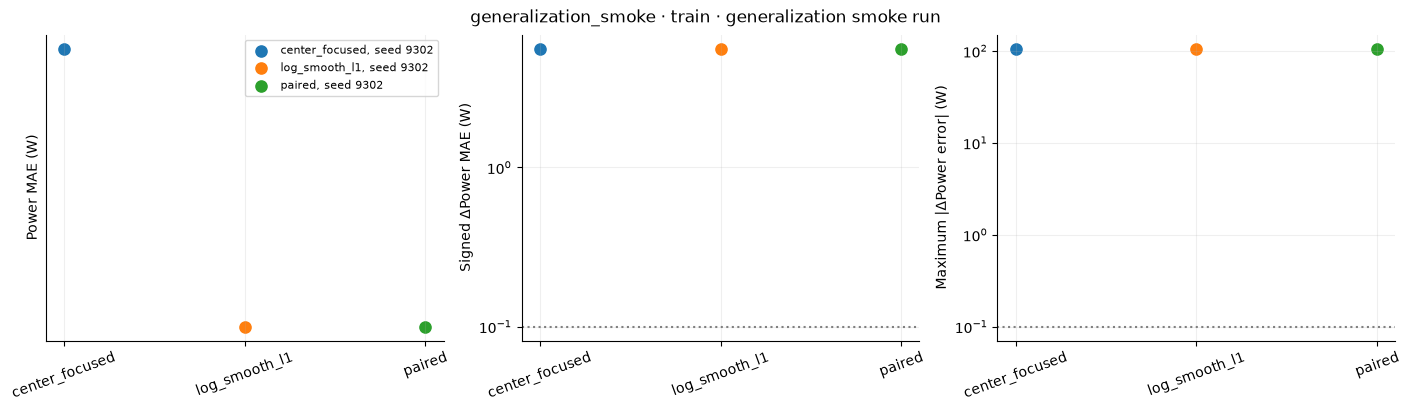

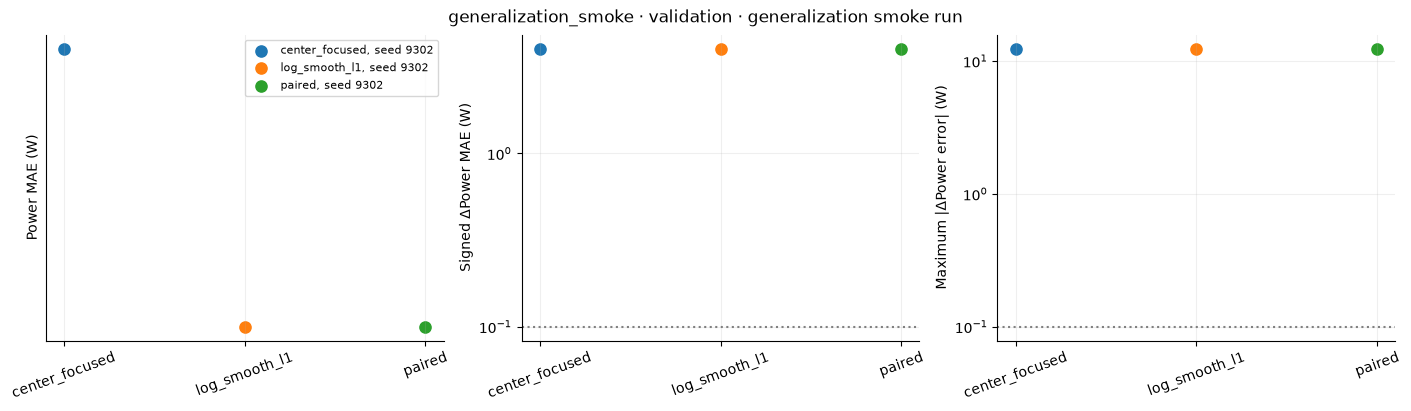

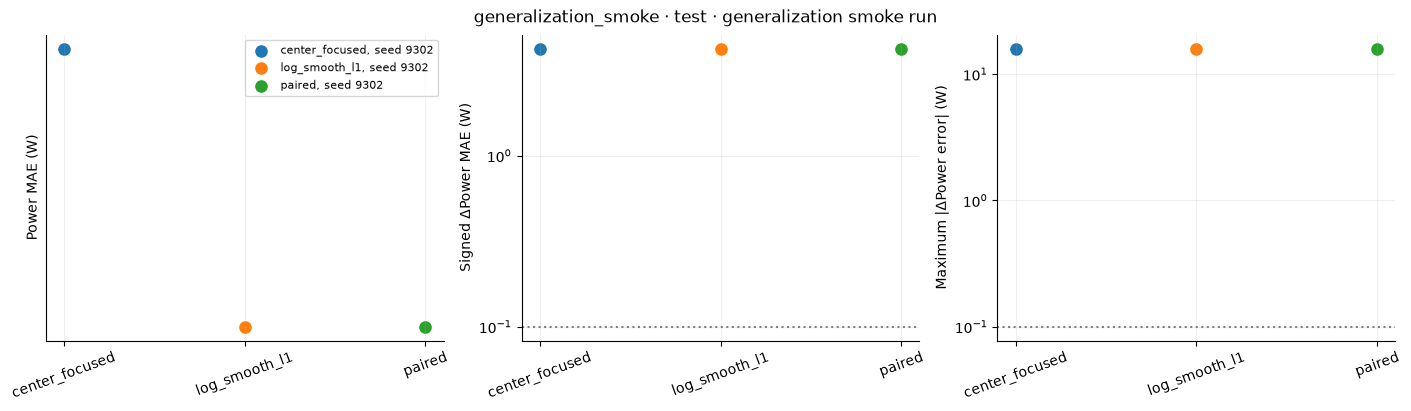

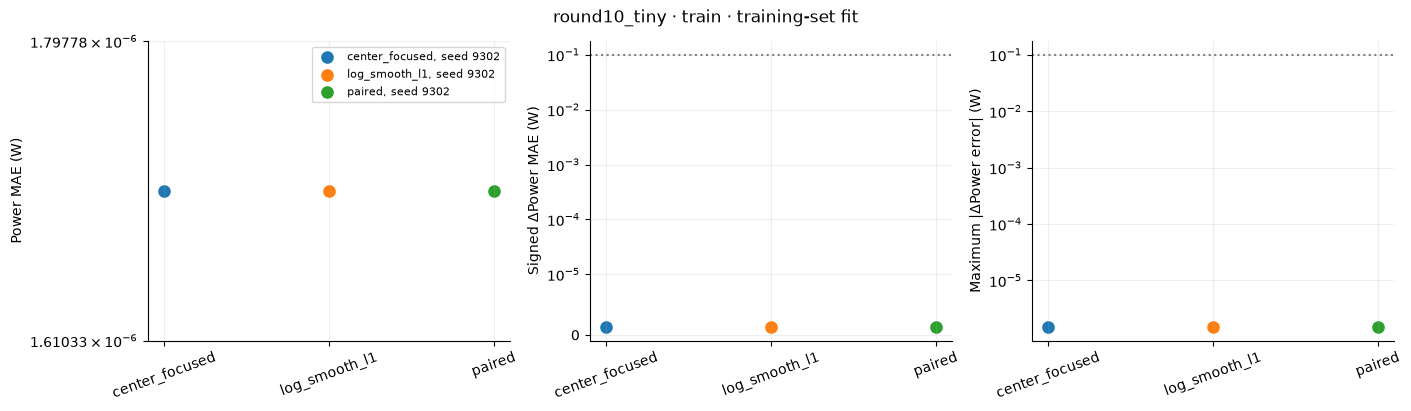

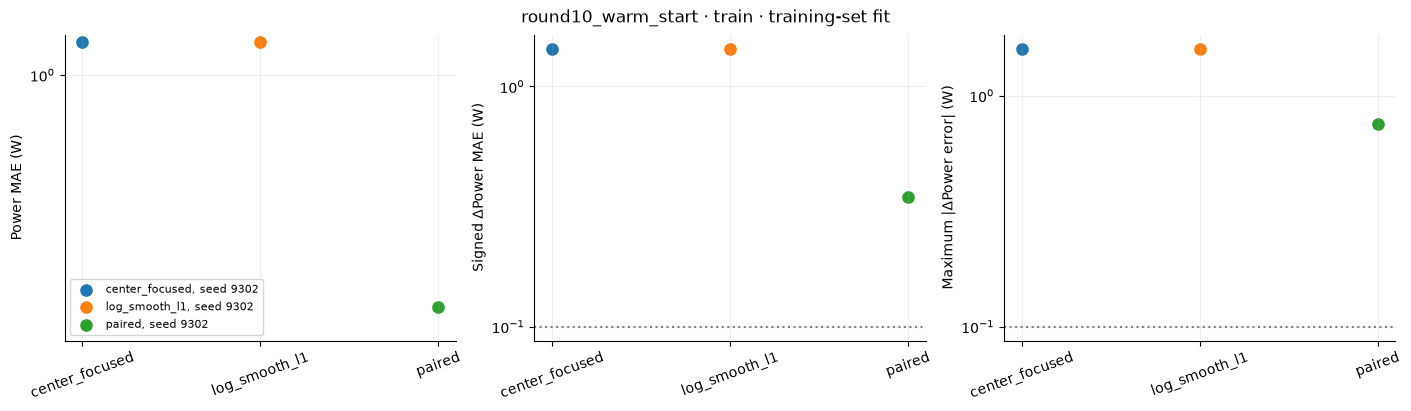

In [7]:
comparison_keys = sorted({(r['experiment'], r['split']) for r in metric_rows},
                         key=lambda key: (key[0], SPLITS.index(key[1]) if key[1] in SPLITS else 99))
for experiment, split in comparison_keys:
    selected = [r for r in metric_rows if r['experiment'] == experiment and r['split'] == split]
    variants = list(dict.fromkeys(r['variant'] for r in selected))
    seeds = list(dict.fromkeys(r['seed'] for r in selected))
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    for ax, field, label in zip(axes,
            ['power_mae', 'delta_mae', 'delta_max_abs_error'],
            ['Power MAE (W)', 'Signed ΔPower MAE (W)', 'Maximum |ΔPower error| (W)']):
        for row in selected:
            offset = (seeds.index(row['seed']) - (len(seeds) - 1) / 2) * 0.08
            ax.scatter(variants.index(row['variant']) + offset, row[field], s=65,
                       color=f'C{variants.index(row["variant"]) % 10}',
                       label=f'{row["variant"]}, seed {row["seed"]}' if row['seed'] is not None else row['variant'])
        ax.set_xticks(range(len(variants)), variants, rotation=20)
        ax.set(ylabel=label, yscale='symlog')
        ax.set_yscale('symlog', linthresh=1e-5)
        if field.startswith('delta'):
            ax.axhline(DELTA_ERROR_TARGET_W, color='grey', ls=':', label='Diagnostic target')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'metrics_{experiment}_{split}')


## Direction-level errors and sign agreement

Both average and worst-case difference errors matter. A small perturbation-cost
error can coexist with wrong individual signs because the cost sums absolute
differences. Blank heatmap cells have no saved metric; sign cells show the number
of differences above the significance threshold.


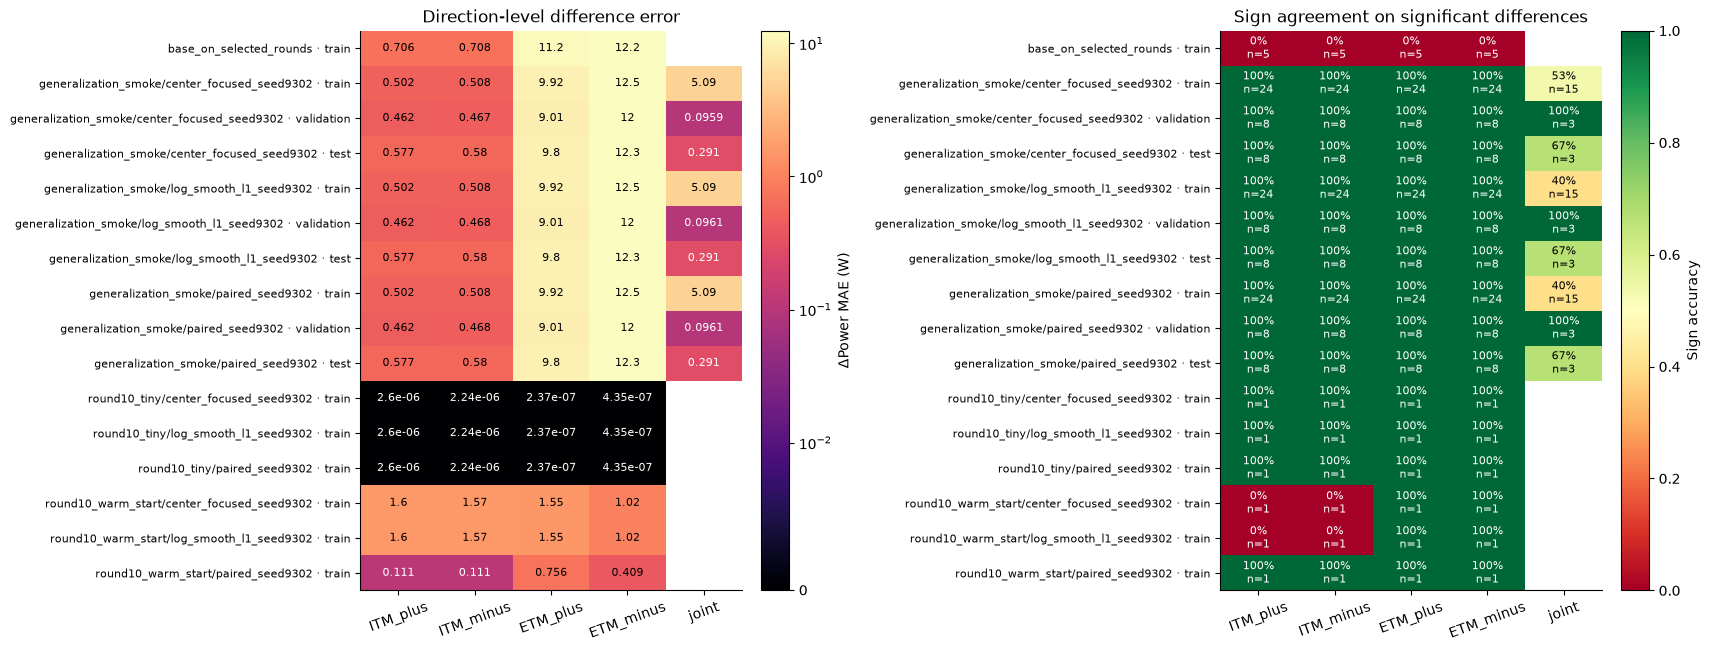

experiment,variant,seed,split,direction,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy
base_on_selected_rounds,checkpoint,—,train,ETM_minus,5,12.1911,15.7791,5,0
base_on_selected_rounds,checkpoint,—,train,ETM_plus,5,11.2384,17.0866,5,0
base_on_selected_rounds,checkpoint,—,train,ITM_minus,5,0.708092,1.65779,5,0
base_on_selected_rounds,checkpoint,—,train,ITM_plus,5,0.706312,1.66766,5,0
generalization_smoke,center_focused,9302,train,ETM_minus,24,12.4715,13.5419,24,1
generalization_smoke,center_focused,9302,train,ETM_plus,24,9.92414,11.1004,24,1
generalization_smoke,center_focused,9302,train,ITM_minus,24,0.507575,0.580069,24,1
generalization_smoke,center_focused,9302,train,ITM_plus,24,0.5019,0.573712,24,1
generalization_smoke,center_focused,9302,train,joint,54,5.09255,106.158,15,0.533333
generalization_smoke,center_focused,9302,validation,ETM_minus,8,12.0402,12.3937,8,1


In [8]:
direction_keys = list(dict.fromkeys((r['run_id'], r['split']) for r in direction_rows))
present_directions = [d for d in DIRECTIONS if any(r['direction'] == d for r in direction_rows)]
if direction_keys and present_directions:
    shape = (len(direction_keys), len(present_directions))
    error_matrix, sign_matrix = np.full(shape, np.nan), np.full(shape, np.nan)
    counts = np.zeros(shape, dtype=int)
    for row in direction_rows:
        i, j = direction_keys.index((row['run_id'], row['split'])), present_directions.index(row['direction'])
        error_matrix[i, j] = row['delta_mae']
        sign_matrix[i, j] = row['sign_accuracy'] if row['sign_accuracy'] is not None else np.nan
        counts[i, j] = row['sign_count']
    fig, axes = plt.subplots(1, 2, figsize=(17, max(5, 0.4 * len(direction_keys))), constrained_layout=True)
    vmax = max(float(np.nanmax(error_matrix)), 0.01)
    error_image = axes[0].imshow(error_matrix, aspect='auto', cmap='magma',
                           norm=SymLogNorm(linthresh=0.01, vmin=0, vmax=vmax))
    fig.colorbar(error_image, ax=axes[0], label='ΔPower MAE (W)')
    sign_image = axes[1].imshow(sign_matrix, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    fig.colorbar(sign_image, ax=axes[1], label='Sign accuracy')
    labels = [f'{run_id} · {split}' for run_id, split in direction_keys]
    for ax in axes:
        ax.set_xticks(range(len(present_directions)), present_directions, rotation=20)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        ax.grid(False)
    for i in range(shape[0]):
        for j in range(shape[1]):
            if np.isfinite(error_matrix[i, j]):
                rgb = error_image.cmap(error_image.norm(error_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[0].text(j, i, f'{error_matrix[i, j]:.3g}', ha='center', va='center', color=color, fontsize=8)
            if np.isfinite(sign_matrix[i, j]):
                rgb = sign_image.cmap(sign_image.norm(sign_matrix[i, j]))[:3]
                color = 'black' if np.dot(rgb, [0.299, 0.587, 0.114]) > 0.5 else 'white'
                axes[1].text(j, i, f'{sign_matrix[i, j]:.0%}\nn={counts[i, j]}', ha='center', va='center', color=color, fontsize=8)
    axes[0].set_title('Direction-level difference error')
    axes[1].set_title('Sign agreement on significant differences')
    show_figure(fig, 'direction_metrics')
table(direction_rows, columns=['experiment', 'variant', 'seed', 'split', 'direction', 'count',
    'delta_mae', 'delta_max_abs_error', 'sign_count', 'sign_accuracy'],
    title='Complete direction metrics', collapsed=True)


## Training trajectories and selected checkpoints

Solid curves show training; dashed curves show the monitored split. Vertical dotted
lines mark each variant's selected epoch. When the monitor is `train`, the two curves
describe the same samples. Epoch zero is retained. Loss components are displayed
within their experiment; different objectives need not have comparable loss values.


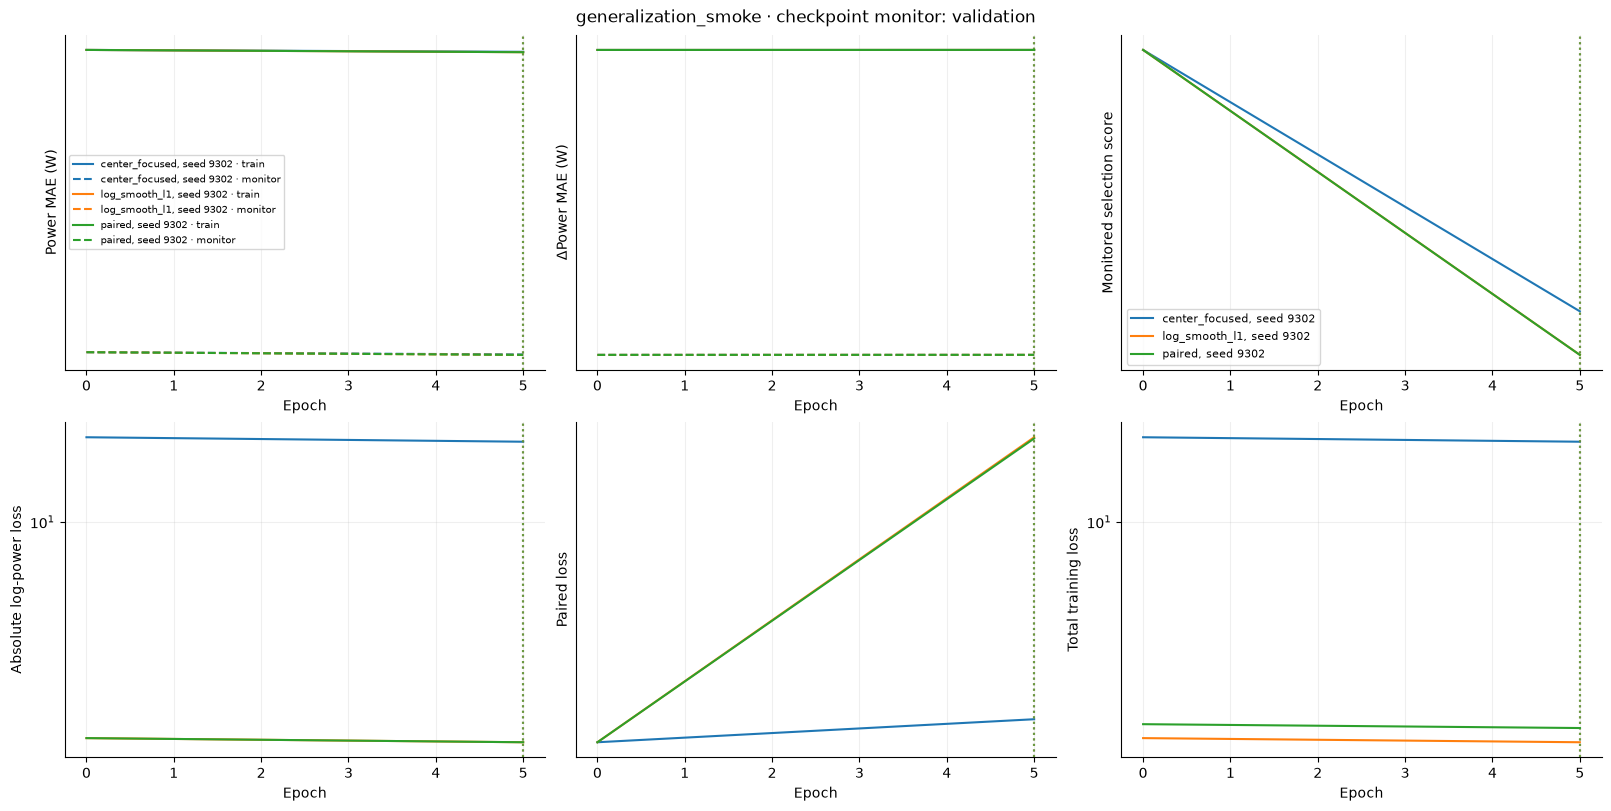

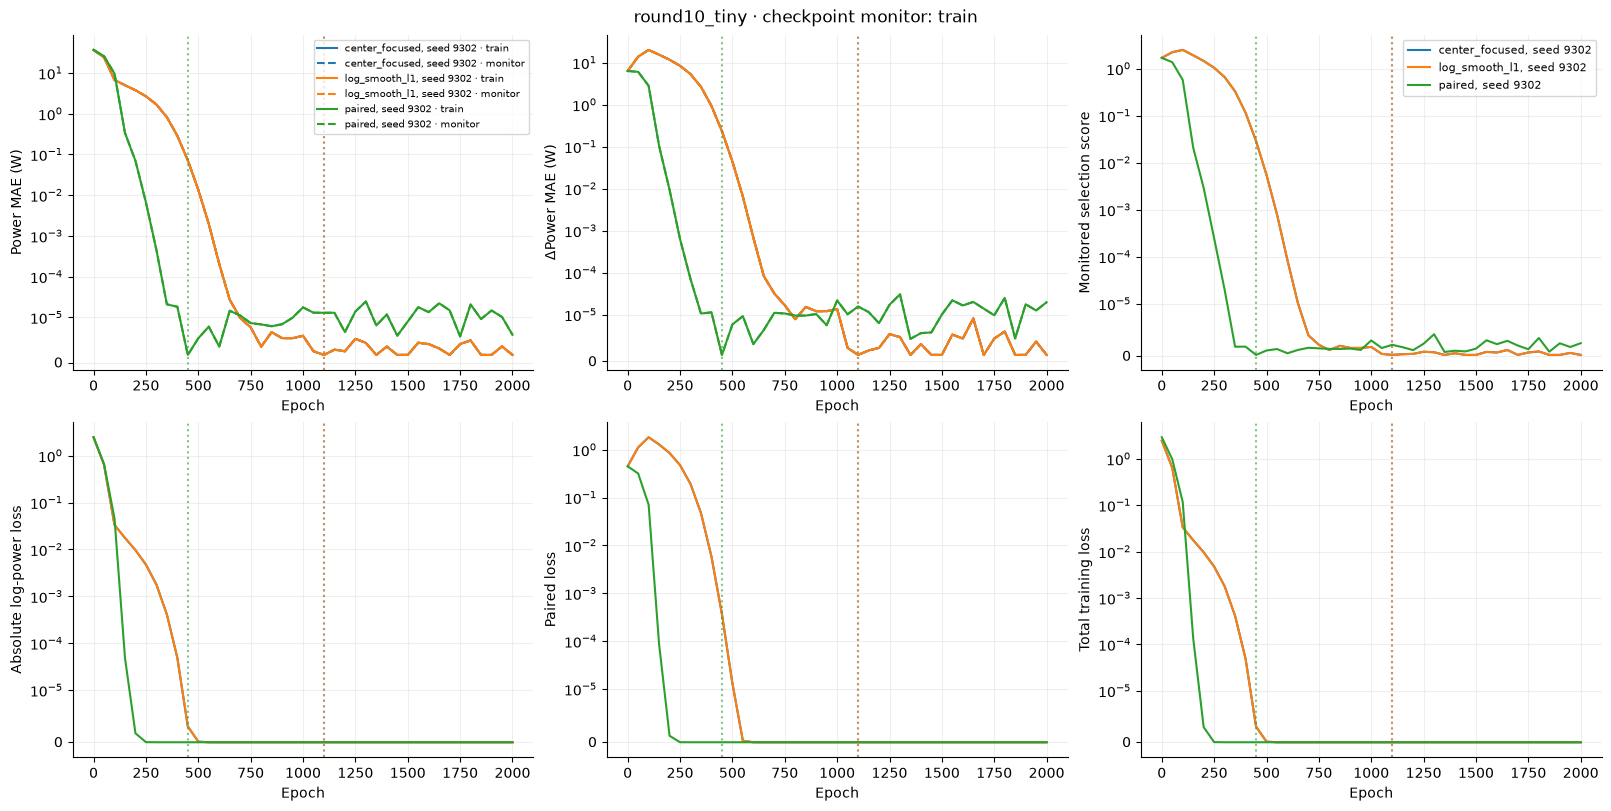

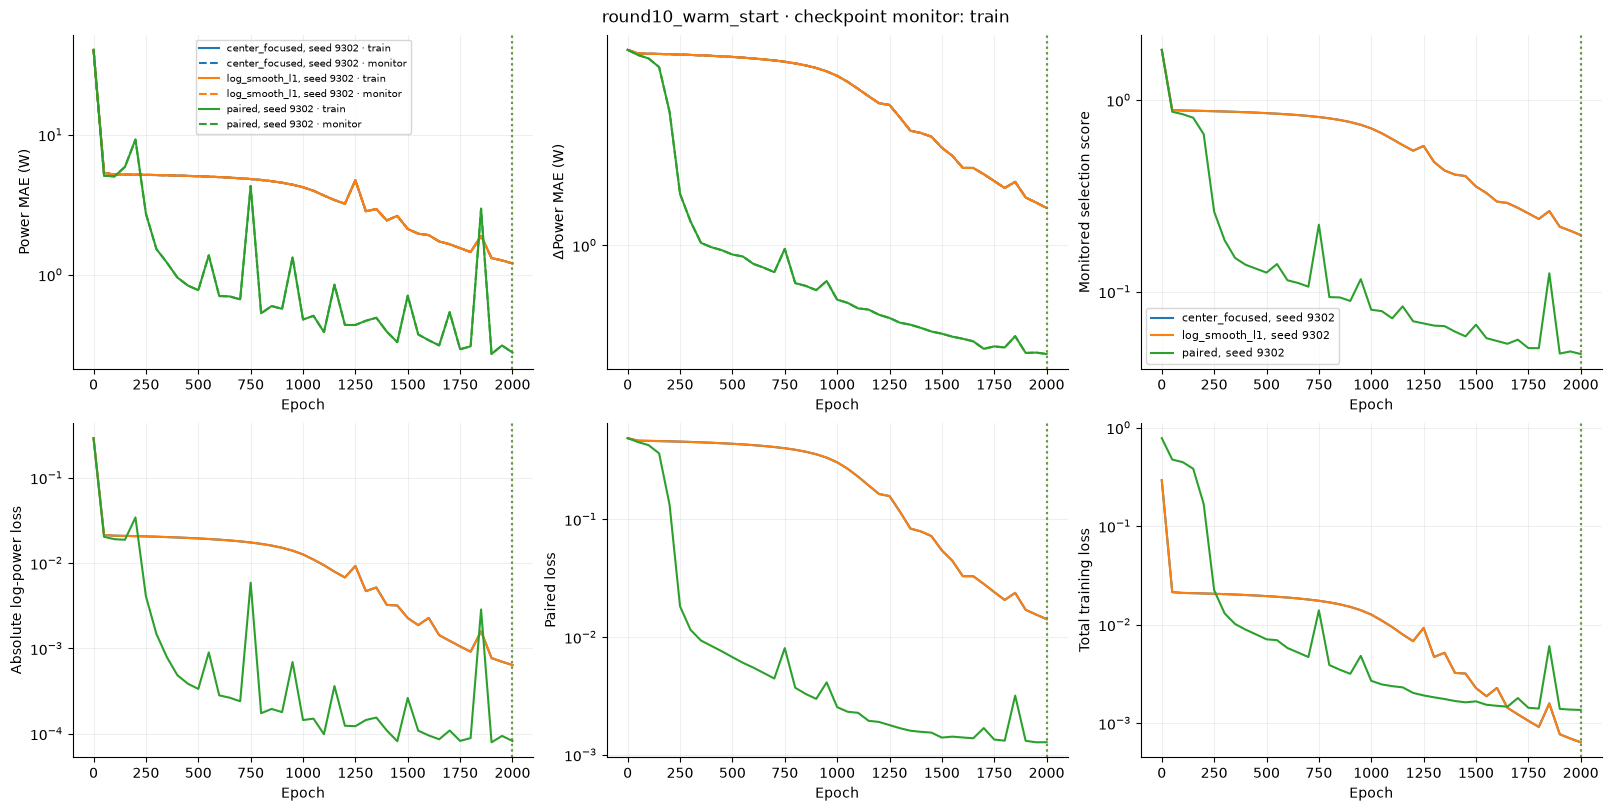

In [9]:
for experiment in experiments:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment and r['history']]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    for index, run in enumerate(selected_runs):
        history, tags = run['history'], run['tags']
        color = f'C{index % 10}'
        label = f'{tags["variant"]}, seed {tags["seed"]}'
        epoch = values(history, 'epoch')
        for ax, field, ylabel in zip(axes[0, :2], ['power_mae', 'delta_mae'], ['Power MAE (W)', 'ΔPower MAE (W)']):
            ax.plot(epoch, values(history, f'train_{field}'), color=color, label=f'{label} · train')
            ax.plot(epoch, values(history, f'monitor_{field}'), '--', color=color, label=f'{label} · monitor')
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        for ax, field, ylabel in zip([axes[0, 2], *axes[1]],
                ['selection_score', 'absolute_loss', 'paired_loss', 'training_loss'],
                ['Monitored selection score', 'Absolute log-power loss', 'Paired loss', 'Total training loss']):
            ax.plot(epoch, values(history, field), color=color, label=label)
            ax.set(xlabel='Epoch', ylabel=ylabel)
            ax.set_yscale('symlog', linthresh=1e-5)
        best_epoch = run['metrics'].get('best_epoch')
        if best_epoch is not None:
            for ax in axes.flat:
                ax.axvline(best_epoch, color=color, ls=':', alpha=0.6)
    axes[0, 0].legend(fontsize=7)
    axes[0, 2].legend(fontsize=8)
    fig.suptitle(f'{experiment} · checkpoint monitor: {selected_runs[0]["metrics"].get("monitor_split")}')
    show_figure(fig, f'training_{experiment}')


## Power, signed differences, and residuals

Each panel compares checkpoints evaluated on the same experiment and split. The
diagonal is exact agreement; residuals are **MLP − saved Finesse** values. Nominal
rows are excluded from difference plots so their identically zero differences do
not inflate agreement. Every saved prediction participates in these plots.


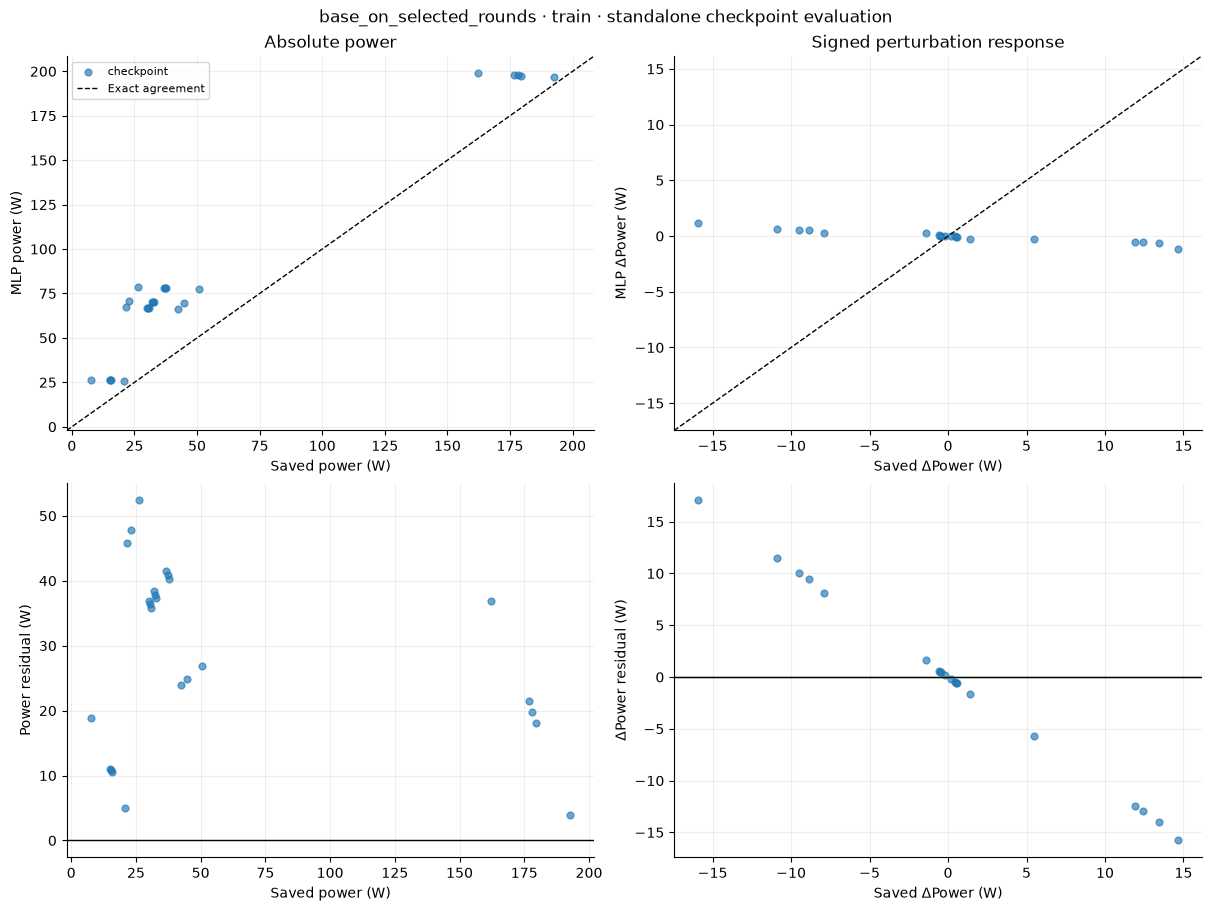

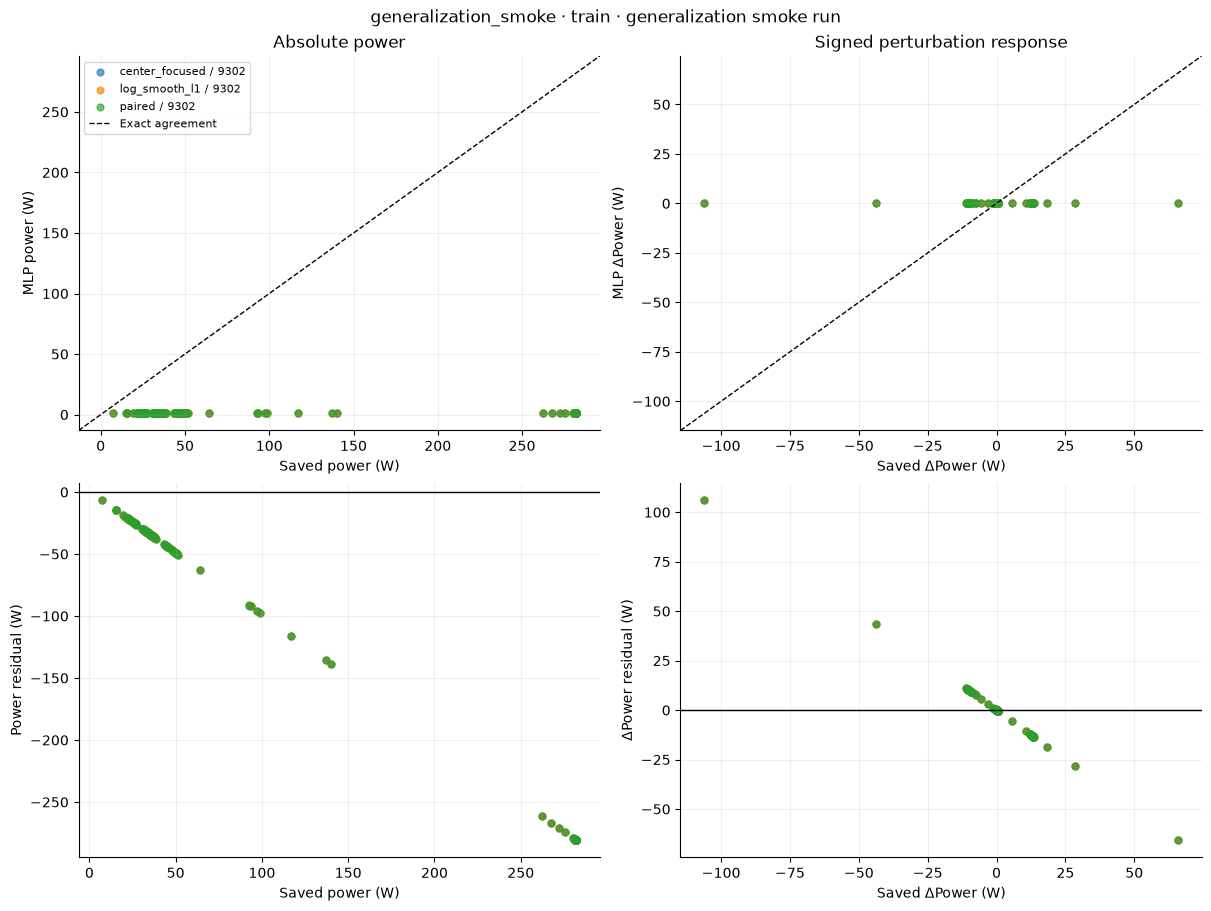

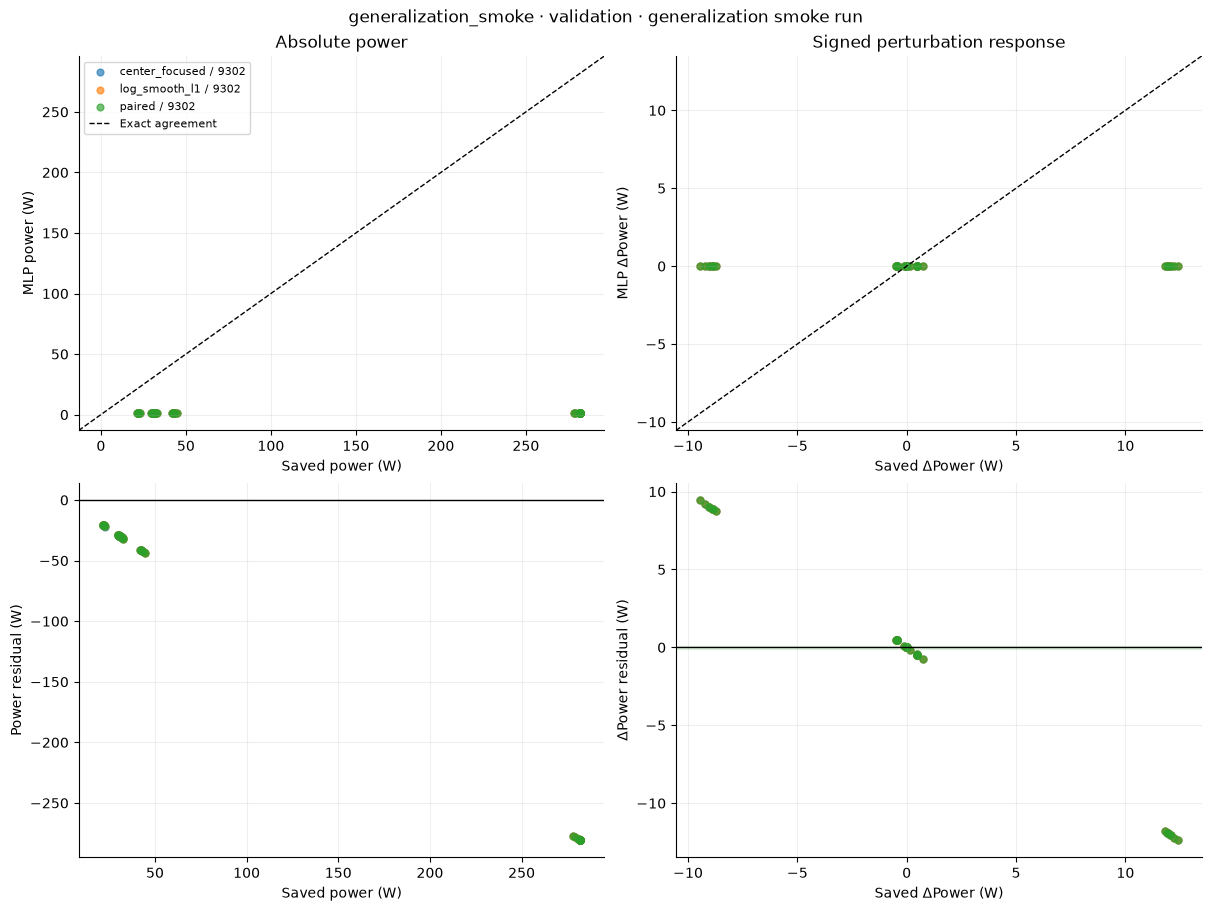

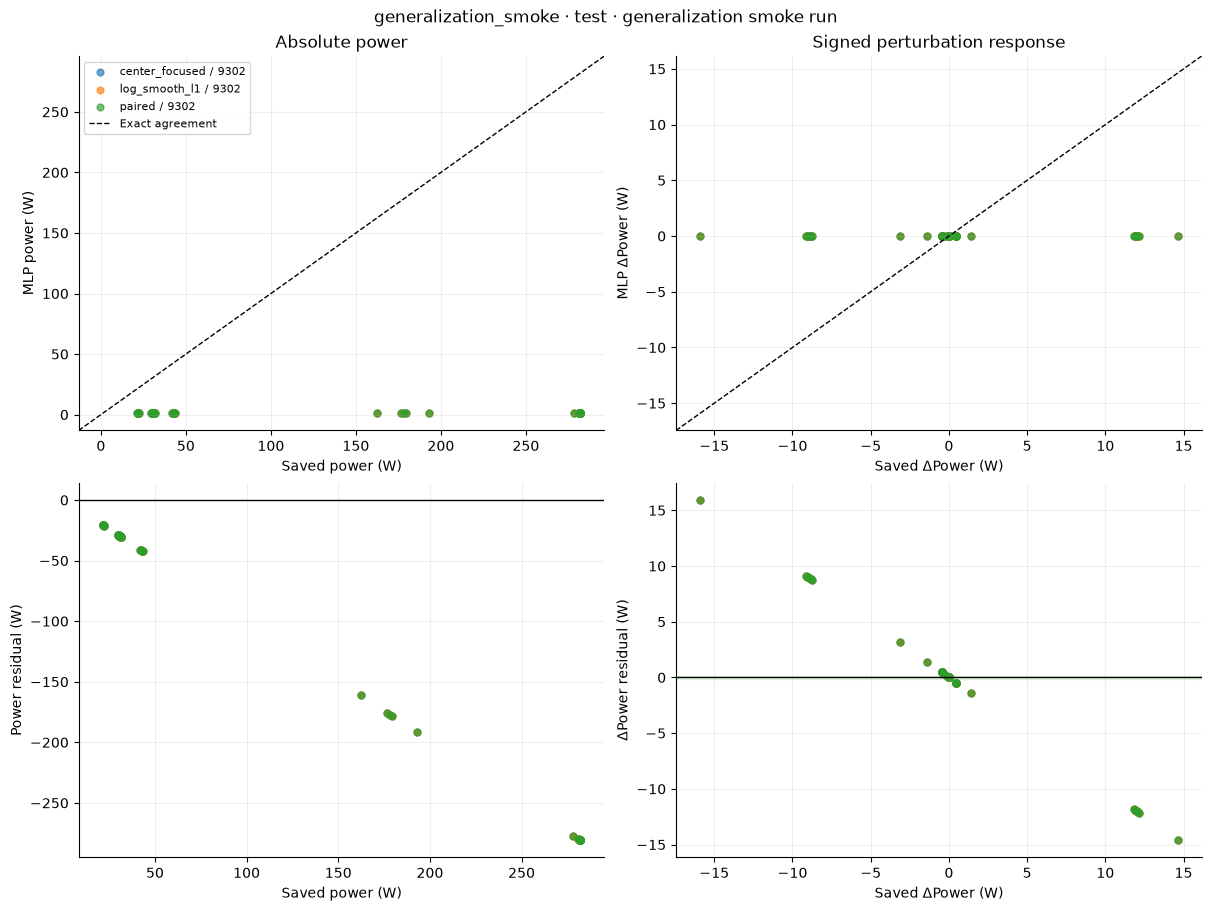

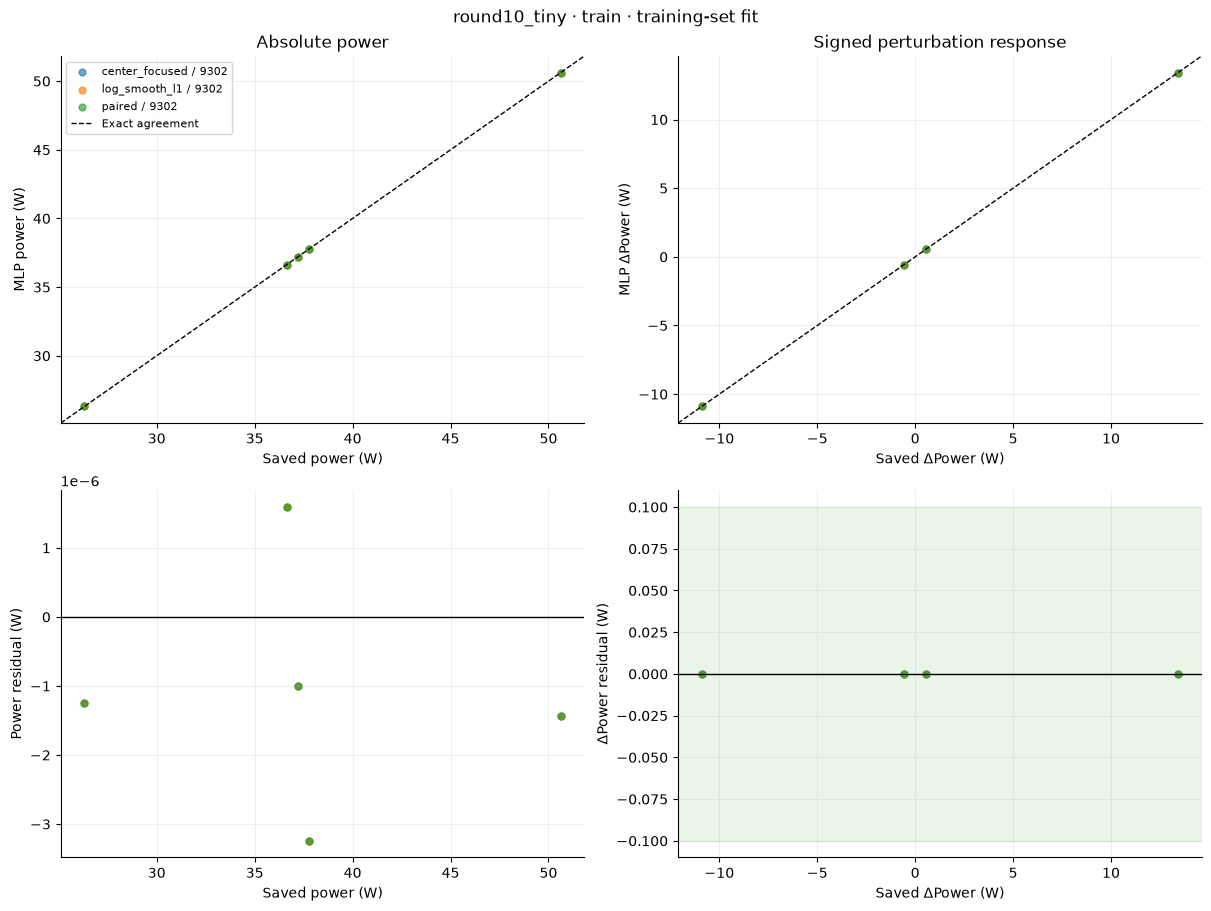

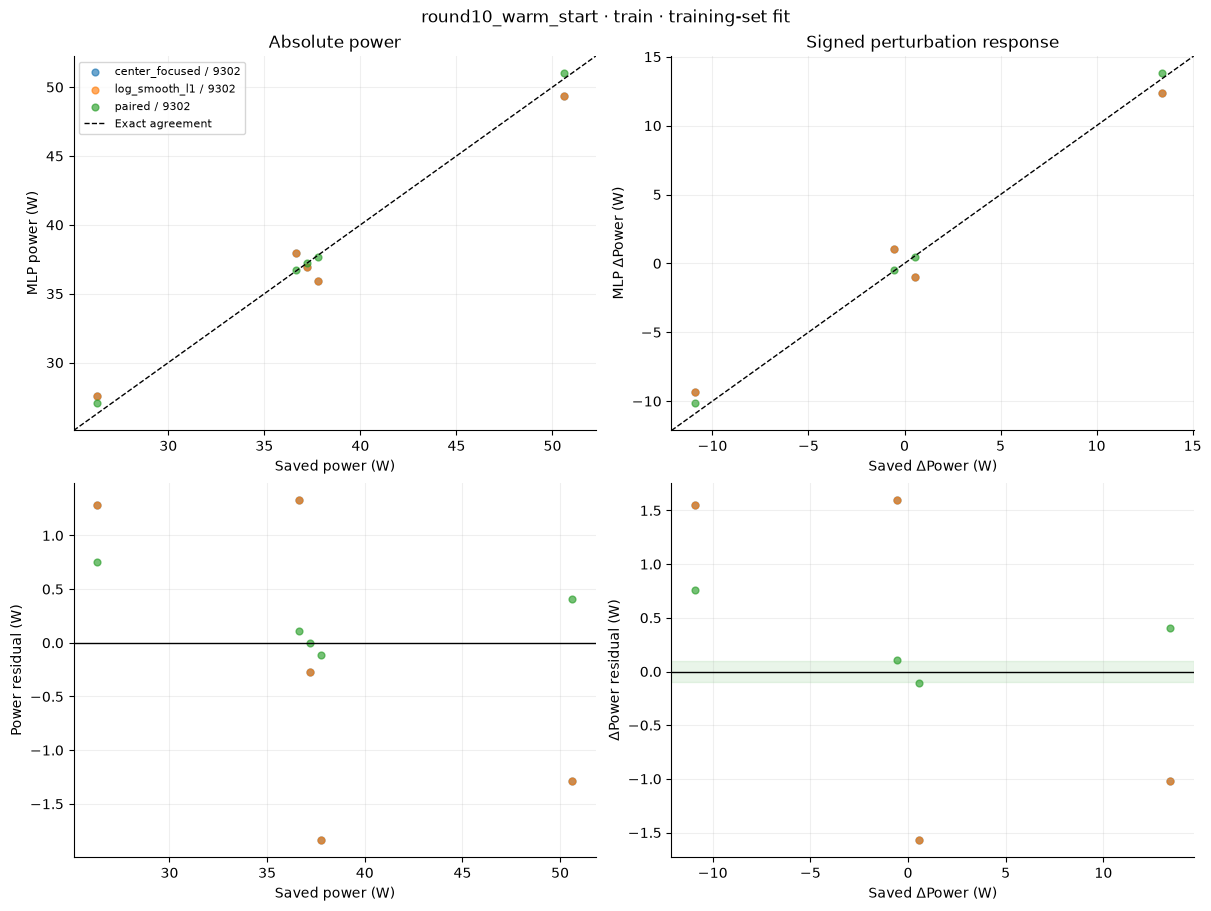

In [10]:
for experiment, split in comparison_keys:
    selected_runs = [r for r in runs.values() if r['tags']['experiment'] == experiment
                     and any(p['split'] == split for p in r['predictions'])]
    if not selected_runs:
        continue
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
    all_power_x, all_power_y, all_delta_x, all_delta_y = [], [], [], []
    for index, run in enumerate(selected_runs):
        rows = [r for r in run['predictions'] if r['split'] == split]
        paired = [r for r in rows if r['direction'] != 'nominal']
        label = run['tags']['variant'] + (f' / {run["tags"]["seed"]}' if run['tags']['seed'] is not None else '')
        color = f'C{index % 10}'
        px, py = values(rows, 'power'), values(rows, 'predicted_power')
        dx, dy = values(paired, 'delta_power'), values(paired, 'predicted_delta_power')
        axes[0, 0].scatter(px, py, color=color, label=label, alpha=0.65, s=24)
        axes[0, 1].scatter(dx, dy, color=color, label=label, alpha=0.65, s=24)
        axes[1, 0].scatter(px, values(rows, 'power_error'), color=color, alpha=0.65, s=24)
        axes[1, 1].scatter(dx, values(paired, 'delta_error'), color=color, alpha=0.65, s=24)
        all_power_x.extend(px); all_power_y.extend(py)
        all_delta_x.extend(dx); all_delta_y.extend(dy)
    parity_line(axes[0, 0], all_power_x, all_power_y)
    parity_line(axes[0, 1], all_delta_x, all_delta_y)
    axes[0, 0].set(xlabel='Saved power (W)', ylabel='MLP power (W)', title='Absolute power')
    axes[0, 1].set(xlabel='Saved ΔPower (W)', ylabel='MLP ΔPower (W)', title='Signed perturbation response')
    axes[1, 0].set(xlabel='Saved power (W)', ylabel='Power residual (W)')
    axes[1, 1].set(xlabel='Saved ΔPower (W)', ylabel='ΔPower residual (W)')
    for ax in axes[1]:
        ax.axhline(0, color='black', lw=1)
    axes[1, 1].axhspan(-DELTA_ERROR_TARGET_W, DELTA_ERROR_TARGET_W, color='tab:green', alpha=0.1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {experiments[experiment]["scope"]}')
    show_figure(fig, f'parity_residuals_{experiment}_{split}')


## Four-direction perturbation cost

The standard `costs.json` tables contain **sum |DeltaPower / DeltaROC|**, in W/m,
for complete five-point feedback groups. The plots here show the perturbation
term. Historical
joint initial pairs cannot define the four-direction cost. Unscorable entries
remain visible as missing values.


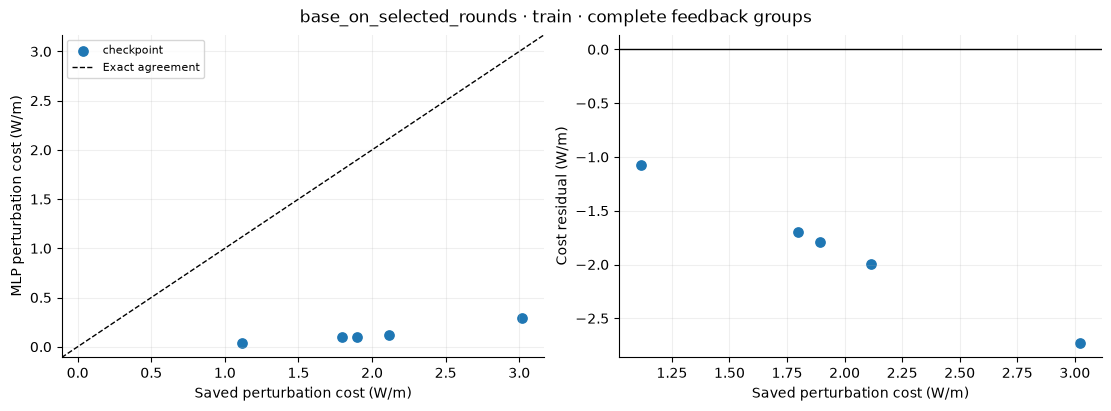

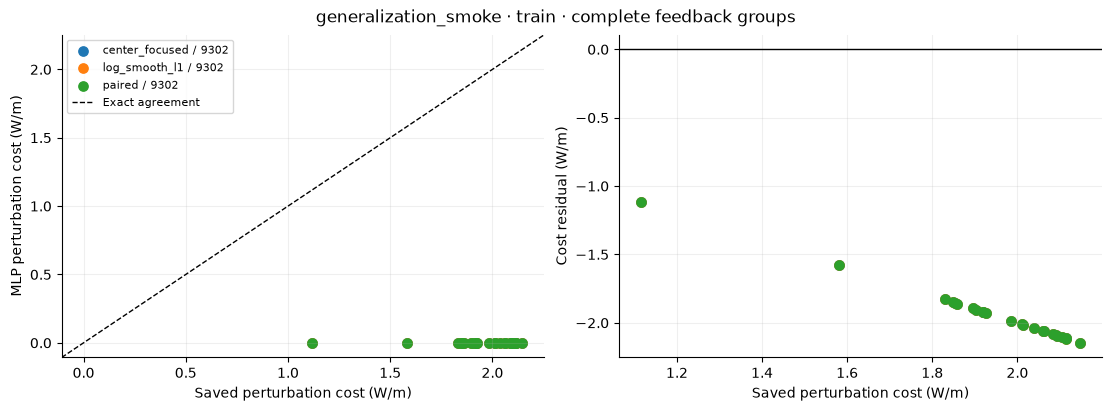

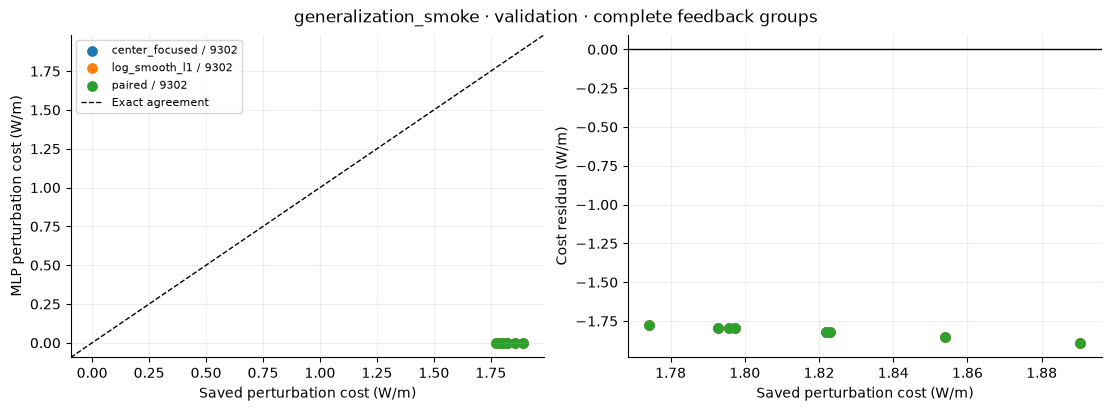

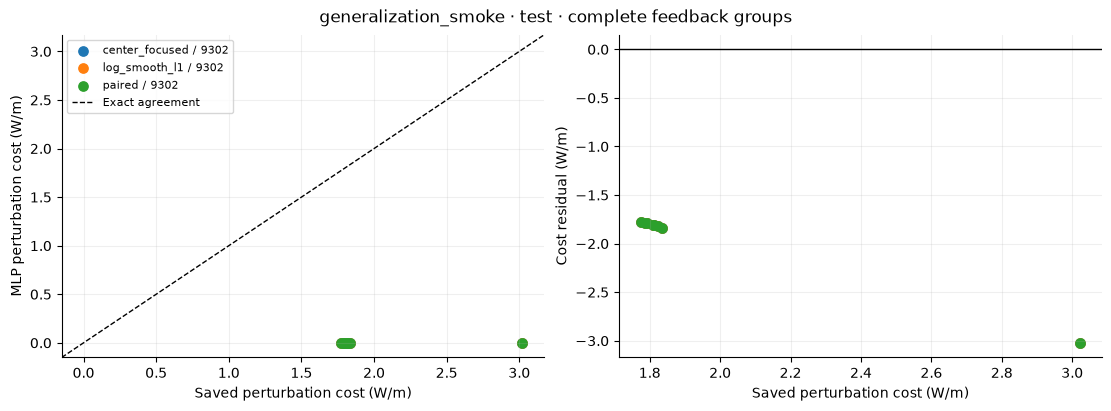

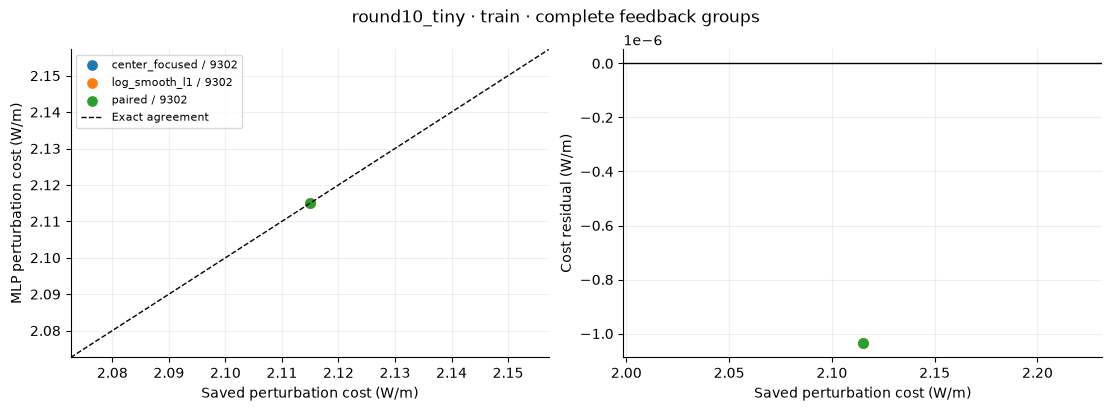

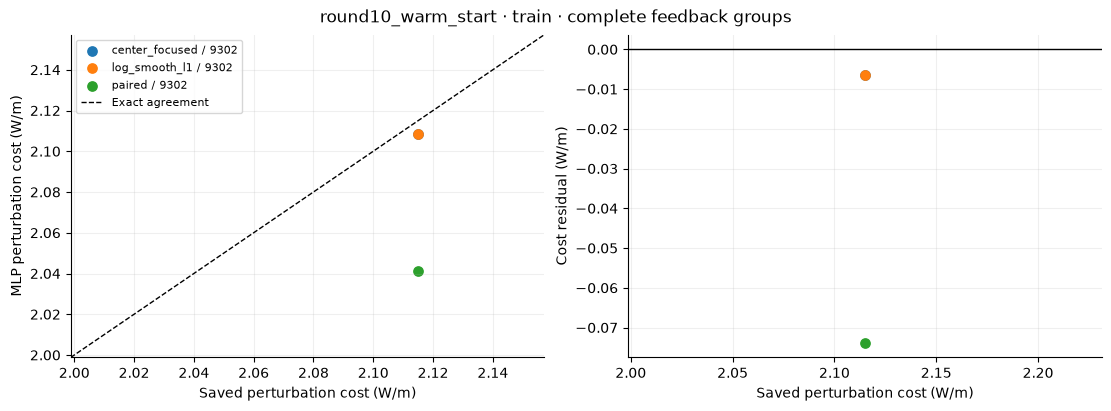

experiment,variant,seed,split,group_id,true_perturbation_cost,predicted_perturbation_cost,cost_error
base_on_selected_rounds,checkpoint,—,train,round:1:0,1.11525,0.0400078,-1.07524
base_on_selected_rounds,checkpoint,—,train,round:10:0,2.11492,0.115444,-1.99947
base_on_selected_rounds,checkpoint,—,train,round:20:0,1.89535,0.104002,-1.79135
base_on_selected_rounds,checkpoint,—,train,round:30:0,1.79724,0.0991522,-1.69809
base_on_selected_rounds,checkpoint,—,train,round:40:0,3.02131,0.29334,-2.72797
generalization_smoke,center_focused,9302,train,round:1:0,1.11525,0.000198509,-1.11505
generalization_smoke,center_focused,9302,train,round:2:0,1.57978,0.000199364,-1.57958
generalization_smoke,center_focused,9302,train,round:3:0,2.05928,0.000199935,-2.05908
generalization_smoke,center_focused,9302,train,round:4:0,2.06241,0.000199933,-2.06221
generalization_smoke,center_focused,9302,train,round:5:0,2.14649,0.00020007,-2.14629


In [11]:
for experiment, split in comparison_keys:
    rows = [r for r in cost_rows if r['experiment'] == experiment and r['split'] == split
            and r['cost_error'] is not None]
    if not rows:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    for index, run_id in enumerate(run_ids):
        current = [r for r in rows if r['run_id'] == run_id]
        label = runs[run_id]['tags']['variant']
        if runs[run_id]['tags']['seed'] is not None:
            label += f' / {runs[run_id]["tags"]["seed"]}'
        axes[0].scatter(values(current, 'true_perturbation_cost'), values(current, 'predicted_perturbation_cost'), label=label, s=45)
        axes[1].scatter(values(current, 'true_perturbation_cost'), values(current, 'cost_error'), label=label, s=45)
    parity_line(axes[0], values(rows, 'true_perturbation_cost'), values(rows, 'predicted_perturbation_cost'))
    axes[0].set(xlabel='Saved perturbation cost (W/m)', ylabel='MLP perturbation cost (W/m)')
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='Saved perturbation cost (W/m)', ylabel='Cost residual (W/m)')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · complete feedback groups')
    show_figure(fig, f'cost_{experiment}_{split}')
table(cost_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id',
    'true_perturbation_cost', 'predicted_perturbation_cost', 'cost_error'],
    title='All saved perturbation costs', collapsed=True)


## Inspect every five-point group

The complete group catalog below includes every saved five-point initial or feedback group.
Change `DETAIL_EXPERIMENT`, `DETAIL_SPLIT`, and `DETAIL_GROUP` in the setup cell, then
rerun the plotting cell. Set `SHOW_ALL_GROUP_RESPONSES = True` to plot the entire
catalog. `plot_group_response(experiment, split, group_id)` also works directly.

Each ITM or ETM curve connects only the three saved samples. It does not represent
a dense simulator sweep. Fixed input q combines geometry and mismatch effects;
one constant-q group's fit cannot establish learned q dependence.


In [12]:
feedback_catalog = []
grouped_predictions = defaultdict(list)
for row in predictions_rows:
    grouped_predictions[(row['experiment'], row['split'], row['group_id'])].append(row)
required_directions = set(DIRECTIONS[:5])
# A response panel must compare the same saved labels for every checkpoint.
for key, rows in grouped_predictions.items():
    references = {}
    for row in rows:
        references.setdefault(row['run_id'], {})[(row['source'], row['h5_key'])] = row['power']
    first = next(iter(references.values()))
    if any(reference != first for reference in references.values()):
        raise ValueError(f'Cannot combine different saved sample selections in group panel {key}.')
for (experiment, split, group_id), rows in sorted(grouped_predictions.items()):
    if not required_directions.issubset({r['direction'] for r in rows}):
        continue
    first_run = rows[0]['run_id']
    reference = [r for r in rows if r['run_id'] == first_run]
    nominal = next(r for r in reference if r['direction'] == 'nominal')
    paired = [r for r in reference if r['direction'] != 'nominal']
    feedback_catalog.append({'experiment': experiment, 'split': split, 'group_id': group_id,
        'nominal_power_W': nominal['power'], 'ITM_ROC_m': nominal['ITM_Rc'],
        'ETM_ROC_m': nominal['ETM_Rc'], 'q_real_m': nominal['q_input_real'],
        'q_imag_m': nominal['q_input_imag'], 'checkpoints': len({r['run_id'] for r in rows}),
        'min_true_delta_W': min(r['delta_power'] for r in paired),
        'max_true_delta_W': max(r['delta_power'] for r in paired)})
table(feedback_catalog, title='All complete five-point groups', collapsed=True)


def plot_group_response(experiment, split, group_id):
    rows = grouped_predictions.get((experiment, split, group_id), [])
    if not rows or not required_directions.issubset({r['direction'] for r in rows}):
        print('No complete feedback group matches these selectors. See feedback_catalog.')
        return
    run_ids = list(dict.fromkeys(r['run_id'] for r in rows))
    reference = [r for r in rows if r['run_id'] == run_ids[0]]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    for column, mirror in enumerate(['ITM', 'ETM']):
        field = f'delta_{mirror.lower()}_roc'
        points = sorted([r for r in reference if r['direction'] == 'nominal' or r['direction'].startswith(mirror)], key=lambda r: r[field])
        for ax, target, ylabel in zip(axes[:, column], ['power', 'delta_power'], ['Power (W)', 'Signed ΔPower (W)']):
            ax.plot(values(points, field), values(points, target), 'o--', color='black', lw=2, label='Saved Finesse samples')
            for index, run_id in enumerate(run_ids):
                predicted = sorted([r for r in rows if r['run_id'] == run_id and
                                    (r['direction'] == 'nominal' or r['direction'].startswith(mirror))], key=lambda r: r[field])
                tags = runs[run_id]['tags']
                label = tags['variant'] + (f' / {tags["seed"]}' if tags['seed'] is not None else '')
                ax.plot(values(predicted, field), values(predicted, f'predicted_{target}'), 'o--', color=f'C{index % 10}', label=label)
            ax.set(xlabel=f'Δ{mirror} ROC (m)', ylabel=ylabel)
        axes[0, column].set_title(mirror)
        axes[1, column].axhline(0, color='grey', lw=1)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{experiment} · {split} · {group_id} · fixed input q\nLines connect sampled points')
    show_figure(fig, f'response_{experiment}_{split}_{group_id}')
    table(rows, columns=['variant', 'seed', 'direction', 'delta_itm_roc', 'delta_etm_roc',
          'power', 'predicted_power', 'power_error', 'delta_power', 'predicted_delta_power', 'delta_error'],
          title=f'{group_id}: every sampled response', collapsed=True)


experiment,split,group_id,nominal_power_W,ITM_ROC_m,ETM_ROC_m,q_real_m,q_imag_m,checkpoints,min_true_delta_W,max_true_delta_W
base_on_selected_rounds,train,round:10:0,37.2047,-1434,3925.91,-104.162,372.18,1,-10.8959,13.4098
base_on_selected_rounds,train,round:1:0,15.3759,-1434,3963.14,-48.2916,258.685,1,-7.89516,5.49777
base_on_selected_rounds,train,round:20:0,32.4011,-1434,3931.34,-96.1173,358.6,1,-9.48975,12.4184
base_on_selected_rounds,train,round:30:0,30.5426,-1434,3933.63,-92.71,352.634,1,-8.88044,11.935
base_on_selected_rounds,train,round:40:0,178.099,-1434,3813.04,-264.308,556.02,1,-15.9224,14.6297
generalization_smoke,test,round:33:0,30.4334,-1434,3933.77,-92.5033,352.268,3,-8.84364,11.9045
generalization_smoke,test,round:34:0,30.3557,-1434,3933.87,-92.3557,352.006,3,-8.81738,11.8826
generalization_smoke,test,round:35:0,30.139,-1434,3934.15,-91.942,351.271,3,-8.74387,11.821
generalization_smoke,test,round:36:0,31.0223,-1434,3933.03,-93.6091,354.221,3,-9.04089,12.0661
generalization_smoke,test,round:37:0,30.8305,-1434,3933.27,-93.2514,353.591,3,-8.97701,12.0143


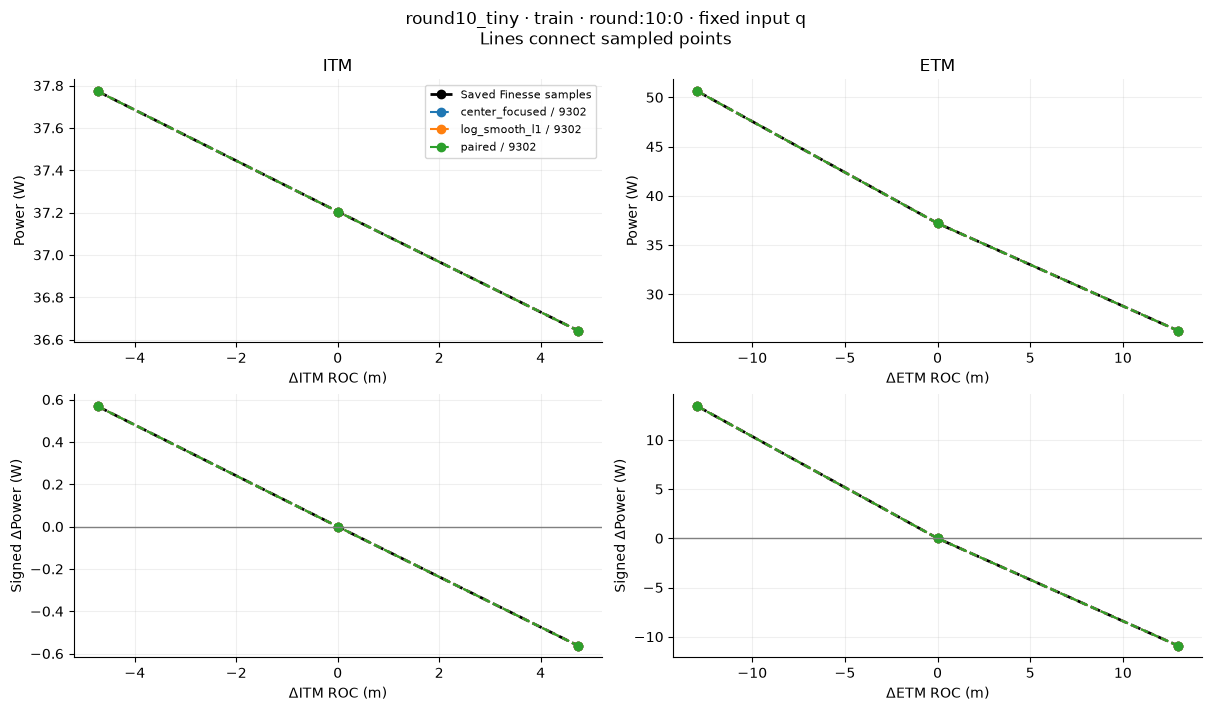

variant,seed,direction,delta_itm_roc,delta_etm_roc,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
center_focused,9302,nominal,0,0,37.2047,37.2047,-1.00522e-06,0,0,0
center_focused,9302,ITM_plus,4.73218,0,36.6428,36.6428,1.59095e-06,-0.561972,-0.561969,2.59617e-06
center_focused,9302,ITM_minus,-4.73218,0,37.773,37.773,-3.24232e-06,0.568235,0.568232,-2.2371e-06
center_focused,9302,ETM_plus,0,12.9556,26.3088,26.3088,-1.2419e-06,-10.8959,-10.8959,-2.36678e-07
center_focused,9302,ETM_minus,0,-12.9556,50.6145,50.6145,-1.4399e-06,13.4098,13.4098,-4.34677e-07
log_smooth_l1,9302,nominal,0,0,37.2047,37.2047,-1.00522e-06,0,0,0
log_smooth_l1,9302,ITM_plus,4.73218,0,36.6428,36.6428,1.59095e-06,-0.561972,-0.561969,2.59617e-06
log_smooth_l1,9302,ITM_minus,-4.73218,0,37.773,37.773,-3.24232e-06,0.568235,0.568232,-2.2371e-06
log_smooth_l1,9302,ETM_plus,0,12.9556,26.3088,26.3088,-1.2419e-06,-10.8959,-10.8959,-2.36678e-07
log_smooth_l1,9302,ETM_minus,0,-12.9556,50.6145,50.6145,-1.4399e-06,13.4098,13.4098,-4.34677e-07


In [13]:
if SHOW_ALL_GROUP_RESPONSES:
    for group in feedback_catalog:
        plot_group_response(group['experiment'], group['split'], group['group_id'])
elif feedback_catalog:
    key = (DETAIL_EXPERIMENT, DETAIL_SPLIT, DETAIL_GROUP)
    available = {(g['experiment'], g['split'], g['group_id']) for g in feedback_catalog}
    if key not in available:
        first = feedback_catalog[0]
        key = (first['experiment'], first['split'], first['group_id'])
        print(f'Configured group unavailable; showing {key}.')
    plot_group_response(*key)
else:
    print('No complete feedback groups saved in the selected experiments.')


## Largest errors and diagnostic checks

The worst sample rows are selected separately for each checkpoint and split, so an
experiment with much larger errors cannot hide failures in another experiment.
The configurable 0.1 W difference-error target is a diagnostic aid for multi-watt
responses, rather than a production acceptance criterion. Both mean and maximum
errors are shown; sign failures and checkpoints selected at the epoch budget are
called out for inspection.


In [14]:
worst_rows, diagnostic_rows = [], []
for row in metric_rows:
    paired = [p for p in runs[row['run_id']]['predictions']
              if p['split'] == row['split'] and p['direction'] != 'nominal']
    worst_rows.extend(sorted(paired, key=lambda p: abs(p['delta_error']), reverse=True)[:TOP_ERRORS_PER_RUN_SPLIT])
    budget = runs[row['run_id']]['config'].get('epochs')
    flags = []
    if row.get('delta_mae', 0) > DELTA_ERROR_TARGET_W:
        flags.append('mean Δ error exceeds target')
    if row.get('delta_max_abs_error', 0) > DELTA_ERROR_TARGET_W:
        flags.append('maximum Δ error exceeds target')
    if row.get('sign_count', 0) == 0:
        flags.append('no significant differences for sign check')
    elif row.get('sign_accuracy') is not None and row['sign_accuracy'] < 1:
        flags.append('some significant Δ signs are wrong')
    if row.get('best_epoch') is not None and budget is not None and row['best_epoch'] == budget:
        flags.append('selected checkpoint is at epoch budget')
    if 'smoke' in row['experiment'].lower():
        flags.append('smoke run: workflow check only')
    diagnostic_rows.append({'experiment': row['experiment'], 'variant': row['variant'],
        'seed': row['seed'], 'split': row['split'], 'scope': row['scope'],
        'checks': '; '.join(flags) or 'within configured Δ error target; inspect context'})
table(worst_rows, columns=['experiment', 'variant', 'seed', 'split', 'group_id', 'h5_key',
    'direction', 'nominal_power', 'power', 'predicted_power', 'power_error',
    'delta_power', 'predicted_delta_power', 'delta_error'],
    title=f'Largest {TOP_ERRORS_PER_RUN_SPLIT} difference errors per checkpoint / split')
table(diagnostic_rows, title='Checks derived from saved metrics')


experiment,variant,seed,split,group_id,h5_key,direction,nominal_power,power,predicted_power,power_error,delta_power,predicted_delta_power,delta_error
base_on_selected_rounds,checkpoint,—,train,round:40:0,sim_3,ETM_plus,178.099,162.176,199.034,36.8578,-15.9224,1.16419,17.0866
base_on_selected_rounds,checkpoint,—,train,round:40:0,sim_4,ETM_minus,178.099,192.729,196.721,3.99199,14.6297,-1.1494,-15.7791
base_on_selected_rounds,checkpoint,—,train,round:10:0,sim_4,ETM_minus,37.2047,50.6145,77.5326,26.918,13.4098,-0.600693,-14.0105
generalization_smoke,center_focused,9302,train,base:59,sim_119,joint,139.956,33.7986,1.21994,-32.5787,-106.157,0.00101902,106.158
generalization_smoke,center_focused,9302,train,base:56,sim_113,joint,31.3778,97.2523,1.00548,-96.2468,65.8745,-0.000198918,-65.8747
generalization_smoke,center_focused,9302,train,base:50,sim_101,joint,137.193,93.4825,1.43351,-92.049,-43.7104,0.00212809,43.7125
generalization_smoke,center_focused,9302,validation,round:25:0,sim_4,ETM_minus,32.303,44.6974,0.947988,-43.7494,12.3945,0.000732743,-12.3937
generalization_smoke,center_focused,9302,validation,round:26:0,sim_4,ETM_minus,31.5987,43.8164,0.947795,-42.8686,12.2177,0.000731278,-12.2169
generalization_smoke,center_focused,9302,validation,round:27:0,sim_4,ETM_minus,31.0167,43.0814,0.947631,-42.1337,12.0646,0.000730056,-12.0639
generalization_smoke,center_focused,9302,test,round:40:0,sim_3,ETM_plus,178.099,162.176,0.969994,-161.206,-15.9224,-0.000898122,15.9215


experiment,variant,seed,split,scope,checks
base_on_selected_rounds,checkpoint,—,train,standalone checkpoint evaluation,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong
generalization_smoke,center_focused,9302,train,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,center_focused,9302,validation,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,center_focused,9302,test,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,log_smooth_l1,9302,train,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,log_smooth_l1,9302,validation,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,log_smooth_l1,9302,test,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,paired,9302,train,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,paired,9302,validation,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; selected checkpoint is at epoch budget; smoke run: workflow check only
generalization_smoke,paired,9302,test,generalization smoke run,mean Δ error exceeds target; maximum Δ error exceeds target; some significant Δ signs are wrong; selected checkpoint is at epoch budget; smoke run: workflow check only


In [15]:
findings = []
for name, record in audits.items():
    audit = record['audit']
    findings.append(f'**{name}:** {audit["rows"]} samples in {audit["groups"]} groups; '
                    f'{audit["valid_fixed_q_groups"]} valid fixed-q groups, '
                    f'{audit["zero_output_rows"]} zero-output rows.')
    check = audit.get('inference_check')
    if check:
        findings.append(f'**{name} feature check:** {check["rows"] - check["mismatches"]}/{check["rows"]} '
                        'saved rows agree with the documented tolerances.')
for name, experiment in experiments.items():
    selected = [r for r in metric_rows if r['experiment'] == name]
    if experiment['scope'] == 'training-set fit':
        train = [r for r in selected if r['split'] == 'train']
        best = min(train, key=lambda r: r['delta_mae']) if train else None
        if best:
            findings.append(f'**{name}:** lowest saved training ΔPower MAE is {best["delta_mae"]:.6g} W '
                            f'({best["variant"]}, seed {best["seed"]}); maximum error is '
                            f'{best["delta_max_abs_error"]:.6g} W. This measures training reconstruction.')
    elif experiment['scope'] == 'generalization smoke run':
        findings.append(f'**{name}:** {experiment["config"].get("epochs")} epochs; '
                        'these held-out tables validate the workflow and do not establish trained model quality.')
    elif experiment['scope'] == 'standalone checkpoint evaluation':
        findings.append(f'**{name}:** existing-model predictions are included; independence from its '
                        'prior training is not established by these saved artifacts.')
    else:
        findings.append(f'**{name}:** checkpoints were monitored on '
                        f'{selected[0].get("monitor_split") if selected else "unspecified"}; '
                        'use validation for choices and preserve the test holdout.')
display(Markdown('\n\n'.join('- ' + finding for finding in findings) or 'No saved findings available.'))


- **run2_audit:** 400 samples in 140 groups; 119 valid fixed-q groups, 41 zero-output rows.

- **run2_selected_feature_audit:** 25 samples in 5 groups; 5 valid fixed-q groups, 0 zero-output rows.

- **run2_selected_feature_audit feature check:** 25/25 saved rows agree with the documented tolerances.

- **base_on_selected_rounds:** existing-model predictions are included; independence from its prior training is not established by these saved artifacts.

- **generalization_smoke:** 5 epochs; these held-out tables validate the workflow and do not establish trained model quality.

- **round10_tiny:** lowest saved training ΔPower MAE is 1.37616e-06 W (center_focused, seed 9302); maximum error is 2.59617e-06 W. This measures training reconstruction.

- **round10_warm_start:** lowest saved training ΔPower MAE is 0.34694 W (paired, seed 9302); maximum error is 0.756251 W. This measures training reconstruction.

## Original written diagnosis

`FINDINGS.md` records the initial analysis and its qualifications. The tables above
are refreshed from the available output files; this historical text may refer to an
earlier set of experiments.


In [16]:
findings_path = DIAGNOSTICS_DIR / 'FINDINGS.md'
if findings_path.exists():
    display(Markdown(findings_path.read_text()))


# Initial run 2 diagnostic results

These are saved-data diagnostics, not a new production model or an independent
accuracy claim. Exact configs and artifact hashes are in the output directories.

## Data and feature audit

The base dataset plus all 40 feedback files contain 140 groups / 400 samples.
Of these, 119 groups have valid fixed input q throughout: 79 initial pairs and
40 feedback groups. There are 41 zero-output rows and 86 rows within the
configured 282.09 ± 0.01 W center band.

Production beam-trace feature extraction was checked for the 25 samples from
rounds 1, 10, 20, 30, and 40. All passed the audit's documented tolerances.
This supports correct fixed-q feature plumbing for those samples; it does not
validate optical power labels, lock convergence, or mode-order convergence.

Artifacts: `outputs/run2_audit/` and `outputs/run2_selected_feature_audit/`.

## Can one group be learned?

Round 10's nominal plus four fixed-q perturbations were fitted for up to 2,000
full-batch AdamW epochs (learning rate 0.001, no weight decay). Every loss
variant shared the same starting state within each experiment. Selection used
the combined normalized training power/difference MAE defined in the README.

| Initialization and normalization | Loss | Power MAE (W) | ΔPower MAE (W) | Maximum ΔPower error (W) |
| --- | --- | ---: | ---: | ---: |
| Fresh weights, local training scaling | Current center-focused | 0.00000170 | 0.00000138 | 0.00000260 |
| Fresh weights, local training scaling | Ordinary log-power | 0.00000170 | 0.00000138 | 0.00000260 |
| Fresh weights, local training scaling | Log-power + paired | 0.00000170 | 0.00000138 | 0.00000260 |
| Run 2 base weights and original scaling | Current center-focused | 1.20285 | 1.43671 | 1.59728 |
| Run 2 base weights and original scaling | Ordinary log-power | 1.20285 | 1.43671 | 1.59728 |
| Run 2 base weights and original scaling | Log-power + paired | 0.27716 | 0.34694 | 0.75625 |

The plateau term is negligible at this group's powers, explaining why the
center-focused and ordinary variants match here. This isolated experiment
cannot assess how plateau examples compete for gradients during full training.

Fresh/local scaling reached its best monitored checkpoint at epoch 1,100 for
ordinary/center-focused loss and epoch 450 for paired loss. All three original-
checkpoint variants selected epoch 2,000, the budget limit; they may still be
improving. Do not interpret the remaining error as a proven capacity limit.

Artifacts and plots: `outputs/round10_tiny/` and
`outputs/round10_warm_start/`. Each has `summary.csv`, `loss_comparison.png`,
and per-variant checkpoint, prediction, history, and figure files.

## What this establishes

- The existing MLP architecture can represent this group's power differences.
- Paired supervision improves this warm-start fit under the same budget.
- Changing both initialization and normalization substantially changes fitting
  difficulty. Their individual effects have not been isolated.
- q is constant within one group, so this does not prove learned q dependence.
- These runs omit the production replay distribution, newest-row weighting,
  regularization, and short fine-tuning budget. They do not diagnose those
  factors individually or establish a production-ready correction.

The next substantive experiment is several-group fitting under both configs,
followed by validation-based comparison on the grouped generalization split.
That config has 78 training, 20 validation, and 21 test groups after excluding
invalid fixed-q groups. A five-epoch smoke run checks the workflow only; it is
not a meaningful model-quality experiment. No full generalization training has
been run as part of this initial verification.


## Full records, configurations, and provenance

Expand a panel to view every saved sample, prediction, or history row and the exact
configuration and source hashes. Nothing in these tables is silently truncated.
The optional saved-figure gallery displays existing PNG artifacts without replacing
them. Checkpoint binaries remain listed in the artifact inventory.


In [17]:
for name, record in audits.items():
    json_panel(f'{name}: audit.json', record['audit'])
    json_panel(f'{name}: config.json', record['config'])
    table(record['samples'], title=f'{name}: all sample records', collapsed=True)
for name, experiment in experiments.items():
    json_panel(f'{name}: config.json', experiment['config'])
    if experiment['provenance']:
        json_panel(f'{name}: provenance.json (groups, exclusions, scales, hashes)', experiment['provenance'])
    summary = read_csv(experiment['path'] / 'summary.csv')
    if summary:
        table(summary, title=f'{name}: saved summary.csv', collapsed=True)
for run_id, run in runs.items():
    json_panel(f'{run_id}: metrics.json', run['metrics'])
    json_panel(f'{run_id}: resolved run config.json', run['config'])
    table(run['predictions'], title=f'{run_id}: all predictions', collapsed=True)
    if run['history']:
        table(run['history'], title=f'{run_id}: full training history', collapsed=True)


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_0,nominal,-2337.62,3194.95,-1300.15,1161.41,282.094,282.094,0,0,0,False,True
all,base:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_1,joint,-2345.34,3184.41,-1300.15,1161.41,282.081,282.094,-0.0130675,-7.71411,-10.5435,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_2,nominal,-3458.16,2917.84,-2666.3,1453.05,282.094,282.094,0,0,0,False,True
all,base:1,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_3,joint,-3469.58,2908.21,-2666.3,1453.05,282.068,282.094,-0.0257878,-11.4119,-9.62891,False,True
all,base:2,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_4,nominal,-1671.86,3670.84,-488.512,760.317,278.125,278.125,0,0,0,False,True
all,base:2,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_5,joint,-1677.38,3658.73,-488.512,760.317,278.863,278.125,0.737555,-5.51709,-12.1138,False,True
all,base:3,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_6,nominal,-3749.51,2679.96,-3367.01,1134.84,282.076,282.076,0,0,0,False,True
all,base:3,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_7,joint,-3737.13,2671.12,-3367.01,1134.84,282.046,282.076,-0.0307038,12.3735,-8.84375,False,True
all,base:4,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_8,nominal,-4022.85,1766.97,0,0,0,0,0,0,0,True,False
all,base:4,/home/xuesi.ma/ligo-opt/MLP/data/run2/base_200.h5,sim_9,joint,-4036.13,1772.81,0,0,0,0,0,-13.2754,5.83093,True,False


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round1.h5,sim_0,nominal,-1434,3963.14,-48.2916,258.685,15.3759,15.3759,0,0,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round1.h5,sim_1,ITM_plus,-1429.27,3963.14,-48.2916,258.685,15.1613,15.3759,-0.214634,4.73218,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round1.h5,sim_2,ITM_minus,-1438.73,3963.14,-48.2916,258.685,15.5928,15.3759,0.216885,-4.73218,0,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round1.h5,sim_3,ETM_plus,-1434,3976.21,-48.2916,258.685,7.48078,15.3759,-7.89516,0,13.0781,False,True
train,round:1:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round1.h5,sim_4,ETM_minus,-1434,3950.06,-48.2916,258.685,20.8737,15.3759,5.49777,0,-13.0784,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_0,nominal,-1434,3925.91,-104.162,372.18,37.2047,37.2047,0,0,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_1,ITM_plus,-1429.27,3925.91,-104.162,372.18,36.6428,37.2047,-0.561972,4.73218,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_2,ITM_minus,-1438.73,3925.91,-104.162,372.18,37.773,37.2047,0.568235,-4.73218,0,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_3,ETM_plus,-1434,3938.87,-104.162,372.18,26.3088,37.2047,-10.8959,0,12.9556,False,True
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_4,ETM_minus,-1434,3912.96,-104.162,372.18,50.6145,37.2047,13.4098,0,-12.9556,False,True


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,5,78,228,141.748,281.004,150,5.57813,106.158,111,0.936937,0.1,24,0,1.94019
center_focused,9302,validation,5,20,64,124.283,280.928,44,4.0229,12.3937,35,1,0.1,8,0,1.81845
center_focused,9302,test,5,21,66,140.027,281,45,4.21893,15.9215,35,0.971429,0.1,8,0,1.95643
log_smooth_l1,9302,train,5,78,228,141.725,281.008,150,5.57839,106.158,111,0.918919,0.1,24,0,1.94033
log_smooth_l1,9302,validation,5,20,64,124.258,280.951,44,4.02319,12.3943,35,1,0.1,8,0,1.81858
log_smooth_l1,9302,test,5,21,66,140.002,281.01,45,4.21917,15.9221,35,0.971429,0.1,8,0,1.95656
paired,9302,train,5,78,228,141.725,281.008,150,5.57839,106.158,111,0.918919,0.1,24,0,1.94033
paired,9302,validation,5,20,64,124.258,280.951,44,4.02319,12.3943,35,1,0.1,8,0,1.81858
paired,9302,test,5,21,66,140.002,281.01,45,4.21917,15.9221,35,0.971429,0.1,8,0,1.95656


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,1100,1,5,1.70406e-06,3.24232e-06,4,1.37616e-06,2.59617e-06,4,1,0.1,1,0,1.03664e-06
log_smooth_l1,9302,train,1100,1,5,1.70406e-06,3.24232e-06,4,1.37616e-06,2.59617e-06,4,1,0.1,1,0,1.03664e-06
paired,9302,train,450,1,5,1.70406e-06,3.24232e-06,4,1.37616e-06,2.59617e-06,4,1,0.1,1,0,1.03664e-06


variant,seed,split,best_epoch,groups,rows,power_mae,power_max_abs_error,count,delta_mae,delta_max_abs_error,sign_count,sign_accuracy,sign_threshold_w,valid_cost_groups,invalid_cost_groups,perturbation_cost_mae
center_focused,9302,train,2000,1,5,1.20285,1.84093,4,1.43671,1.59728,4,0.5,0.1,1,0,0.00645422
log_smooth_l1,9302,train,2000,1,5,1.20285,1.84093,4,1.43671,1.59728,4,0.5,0.1,1,0,0.00645422
paired,9302,train,2000,1,5,0.277163,0.75431,4,0.34694,0.756251,4,1,0.1,1,0,0.0738441


...

epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.291063,0.488863,0.291063,40.4264,6.68762,40.4264,6.68762,1.82356,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
50,0.0213321,0.465648,0.0213321,5.35188,6.45883,5.35188,6.45883,0.885863,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
100,0.0209354,0.463788,0.0209354,5.19467,6.44363,5.19467,6.44363,0.880021,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
150,0.0208215,0.461862,0.0208215,5.19768,6.42864,5.19768,6.42864,0.878366,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
200,0.0206877,0.459584,0.0206877,5.18478,6.41097,5.18478,6.41097,0.875988,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
250,0.0205335,0.456951,0.0205335,5.16858,6.39055,5.16858,6.39055,0.873206,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
300,0.0203594,0.453967,0.0203594,5.15004,6.36739,5.15004,6.36739,0.870046,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
350,0.0201649,0.450617,0.0201649,5.12922,6.34136,5.12922,6.34136,0.866496,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
400,0.0199486,0.446873,0.0199486,5.10594,6.31224,5.10594,6.31224,0.862524,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit
450,0.019708,0.442685,0.019708,5.07987,6.27963,5.07987,6.27963,0.858075,round10_warm_start,round10_warm_start/center_focused_seed9302,center_focused,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_0,nominal,-1434,3925.91,-104.162,372.18,37.2047,37.2047,0,0,0,False,True,36.9373,-0.267404,0,0,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_1,ITM_plus,-1429.27,3925.91,-104.162,372.18,36.6428,37.2047,-0.561972,4.73218,0,False,True,37.9726,1.32987,1.0353,1.59728,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_2,ITM_minus,-1438.73,3925.91,-104.162,372.18,37.773,37.2047,0.568235,-4.73218,0,False,True,35.932,-1.84093,-1.00529,-1.57353,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_3,ETM_plus,-1434,3938.87,-104.162,372.18,26.3088,37.2047,-10.8959,0,12.9556,False,True,27.5938,1.28496,-9.34357,1.55236,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_4,ETM_minus,-1434,3912.96,-104.162,372.18,50.6145,37.2047,13.4098,0,-12.9556,False,True,49.3234,-1.29109,12.3861,-1.02369,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.291063,0.488863,0.291063,40.4264,6.68762,40.4264,6.68762,1.82356,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
50,0.0213321,0.465648,0.0213321,5.35188,6.45883,5.35188,6.45883,0.885863,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
100,0.0209354,0.463788,0.0209354,5.19467,6.44363,5.19467,6.44363,0.880021,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
150,0.0208215,0.461862,0.0208215,5.19768,6.42864,5.19768,6.42864,0.878366,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
200,0.0206877,0.459584,0.0206877,5.18478,6.41097,5.18478,6.41097,0.875988,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
250,0.0205335,0.456951,0.0205335,5.16858,6.39055,5.16858,6.39055,0.873206,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
300,0.0203594,0.453967,0.0203594,5.15004,6.36739,5.15004,6.36739,0.870046,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
350,0.0201649,0.450617,0.0201649,5.12922,6.34136,5.12922,6.34136,0.866496,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
400,0.0199486,0.446873,0.0199486,5.10594,6.31224,5.10594,6.31224,0.862524,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit
450,0.019708,0.442685,0.019708,5.07987,6.27963,5.07987,6.27963,0.858075,round10_warm_start,round10_warm_start/log_smooth_l1_seed9302,log_smooth_l1,9302,p_ITM_p2_i,training-set fit


split,group_id,source,h5_key,direction,ITM_Rc,ETM_Rc,q_input_real,q_input_imag,power,nominal_power,delta_power,delta_itm_roc,delta_etm_roc,zero_output,valid_fixed_q_group,predicted_power,power_error,predicted_delta_power,delta_error,experiment,run_id,variant,seed,detector,scope
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_0,nominal,-1434,3925.91,-104.162,372.18,37.2047,37.2047,0,0,0,False,True,37.2028,-0.00194111,0,0,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_1,ITM_plus,-1429.27,3925.91,-104.162,372.18,36.6428,37.2047,-0.561972,4.73218,0,False,True,36.7522,0.109482,-0.450549,0.111423,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_2,ITM_minus,-1438.73,3925.91,-104.162,372.18,37.773,37.2047,0.568235,-4.73218,0,False,True,37.6599,-0.113098,0.457078,-0.111157,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_3,ETM_plus,-1434,3938.87,-104.162,372.18,26.3088,37.2047,-10.8959,0,12.9556,False,True,27.0631,0.75431,-10.1397,0.756251,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
train,round:10:0,/home/xuesi.ma/ligo-opt/MLP/data/run2/round10.h5,sim_4,ETM_minus,-1434,3912.96,-104.162,372.18,50.6145,37.2047,13.4098,0,-12.9556,False,True,51.0215,0.406987,13.8187,0.408928,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


epoch,absolute_loss,paired_loss,training_loss,train_power_mae,train_delta_mae,monitor_power_mae,monitor_delta_mae,selection_score,experiment,run_id,variant,seed,detector,scope
0,0.291063,0.488863,0.779926,40.4264,6.68762,40.4264,6.68762,1.82356,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
50,0.0203241,0.452792,0.473116,5.09486,6.35825,5.09486,6.35825,0.867556,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
100,0.0190498,0.426324,0.445373,5.03419,6.15184,5.03419,6.15184,0.842112,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
150,0.0187563,0.363235,0.381992,5.8993,5.65729,5.8993,5.65729,0.807405,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
200,0.0342843,0.133193,0.167478,9.23814,3.65896,9.23814,3.65896,0.663087,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
250,0.00407236,0.0182346,0.022307,2.72836,1.64801,2.72836,1.64801,0.261439,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
300,0.00147811,0.0115069,0.0129851,1.52407,1.26085,1.52407,1.26085,0.185385,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
350,0.000789617,0.00933633,0.010126,1.21931,1.02264,1.21931,1.02264,0.149924,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
400,0.000484904,0.00839653,0.00888143,0.954506,0.980351,0.954506,0.980351,0.138154,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit
450,0.000385619,0.00755427,0.00793989,0.836093,0.95212,0.836093,0.95212,0.131813,round10_warm_start,round10_warm_start/paired_seed9302,paired,9302,p_ITM_p2_i,training-set fit


In [18]:
saved_figures = sorted({p for record in [*audits.values(), *experiments.values()]
                        for p in record['path'].rglob('*.png')})
if SHOW_SAVED_FIGURES:
    for path in saved_figures:
        display(Markdown(f'**{path.relative_to(DIAGNOSTICS_DIR).as_posix()}**'))
        display(Image(filename=str(path)))
else:
    print(f'{len(saved_figures)} saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.')
print(f'Rendered {figure_count} diagnostic figures from saved results.')
if EXPORT_FIGURES:
    print(f'Exported PNG figures to {EXPORT_DIR}')


20 saved PNG artifacts available. Set SHOW_SAVED_FIGURES=True to display all.
Rendered 26 diagnostic figures from saved results.
